# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** [Input Nama Anda]
- **Email:** [Input Email Anda]
- **ID Dicoding:** [Input Username Dicoding Anda]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam dan berorientasi tindakan:

* **Specific (Spesifik):** Pertanyaan jelas, fokus pada topik, segmen, atau variabel tertentu, dan tidak bermakna ganda.
* **Measurable (Terukur):** Pertanyaan dapat dijawab dengan angka, metrik kuantitatif, persentase, atau agregasi statistik yang konkret.
* **Action-Oriented (Berorientasi Aksi):** Jawaban dari pertanyaan memberikan arahan nyata bagi *stakeholder* untuk mengambil keputusan operasional atau strategis.
* **Relevant (Relevan):** Pertanyaan selaras dengan masalah utama dan tujuan bisnis sistem penyewaan sepeda (*Capital Bikeshare*).
* **Time-bound (Terikat Waktu):** Pertanyaan memiliki batasan periode waktu analisis yang jelas (periode historis 2011–2012).

### Rumusan Pertanyaan Bisnis (Berbasis Metode SMART)

- **Pertanyaan 1:** *"Seberapa besar pengaruh variasi musim (Spring, Summer, Fall, Winter) dan kondisi cuaca (Clear hingga Heavy Rain/Snow) terhadap rata-rata serta total penyewaan sepeda harian (`cnt`, `casual`, dan `registered`) pada sistem Capital Bikeshare selama periode tahun 2011–2012, dan pada kondisi apa terjadi penurunan penyewaan paling drastis yang memerlukan intervensi strategi operasional?"*
  - **Specific:** Berfokus secara spesifik pada dampak 4 kategori musim dan 4 kategori kondisi cuaca terhadap jumlah penyewaan harian (`cnt`, `casual`, `registered`).
  - **Measurable:** Diukur menggunakan rata-rata penyewaan harian (unit/hari), total penyewaan, serta persentase selisih/penurunan (`% drop`) antar musim dan kondisi cuaca.
  - **Action-Oriented:** Menjadi dasar penjadwalan perawatan armada (*fleet maintenance*) pada musim sepi serta penerapan promo dinamis berbasis cuaca.
  - **Relevant:** Permintaan penyewaan sepeda luar ruang sangat sensitif terhadap faktor cuaca dan musim, sehingga krusial untuk efisiensi biaya operasional.
  - **Time-bound:** Dianalisis pada rentang data historis dua tahun penuh (Januari 2011 – Desember 2012).

- **Pertanyaan 2:** *"Bagaimana perbedaan pola distribusi penyewaan sepeda per jam (00:00–23:00) antara segmen pengguna terdaftar (`registered`) dan pengguna kasual (`casual`) pada hari kerja (`workingday`) dibandingkan hari libur/akhir pekan (`holiday/weekend`) sepanjang periode 2011–2012, serta pada jam berapa terjadi puncak permintaan tertinggi (peak hours) yang membutuhkan redistribusi armada?"*
  - **Specific:** Membandingkan pola utilisasi per jam (00:00–23:00) antara segmen `registered` dan `casual` pada hari kerja vs hari libur/akhir pekan.
  - **Measurable:** Diukur dengan rata-rata jumlah penyewaan per jam (unit/jam) serta rasio kontribusi (`% share`) tiap segmen pada jam sibuk (*peak hours*).
  - **Action-Oriented:** Mengarahkan penjadwalan *rebalancing* (redistribusi sepeda antar stasiun) sebelum jam puncak komuter dan perancangan paket bundel akhir pekan untuk pengguna `casual`.
  - **Relevant:** Mencegah kekosongan sepeda (*stockout*) atau penumpukan stasiun (*dock overflow*) pada jam kritis yang berdampak langsung pada kepuasan pelanggan.
  - **Time-bound:** Mencakup pola 24 jam harian sepanjang periode tahun 2011–2012.

- **Pertanyaan 3:** *"Berapa persentase tingkat pertumbuhan jumlah penyewaan sepeda secara tahunan (Year-over-Year) dan bagaimana tren pergerakan bulanan dari segmen pengguna `casual` dan `registered` antara tahun 2011 dan tahun 2012 untuk mengidentifikasi periode ekspansi kapasitas armada yang optimal?"*
  - **Specific:** Menganalisis pertumbuhan tahunan (*Year-over-Year*) dan lintasan tren bulanan (Januari–Desember) pada segmen `casual` dan `registered`.
  - **Measurable:** Diukur menggunakan total dan rata-rata penyewaan tahunan/bulanan serta persentase pertumbuhan (`% YoY Growth`) dari tahun 2011 ke 2012.
  - **Action-Oriented:** Menentukan waktu terbaik bagi manajemen untuk menambah kapasitas unit sepeda baru dan meluncurkan kampanye akuisisi *annual membership* sebelum bulan puncak.
  - **Relevant:** Menilai performa ekspansi pasar Capital Bikeshare dan mengoptimalkan akuisisi pelanggan jangka panjang.
  - **Time-bound:** Membandingkan secara langsung performa bulanan dan tahunan antara tahun 2011 dan tahun 2012.

## Import Semua Packages/Library yang Digunakan

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")

# Konfigurasi tampilan tabel dan visualisasi agar konsisten, bersih, dan mudah dibaca
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10
plt.rcParams["figure.dpi"] = 110

print("Seluruh library berhasil dimuat dengan sukses.")

Seluruh library berhasil dimuat dengan sukses.


## Data Wrangling

### Gathering Data
Pada tahap ini, kita memuat kedua dataset utama dari **Bike Sharing Dataset**, yaitu:
1. `day.csv`: Data penyewaan sepeda yang diagregasi secara harian (*daily basis*).
2. `hour.csv`: Data penyewaan sepeda yang diagregasi secara per jam (*hourly basis*).

#### Load Tabel `day_df` dan `hour_df`

In [2]:
# Menentukan path fleksibel ke folder Bike-sharing-dataset
DATA_DIR = Path("Bike-sharing-dataset")
if not DATA_DIR.exists():
    DATA_DIR = Path(r"C:\Users\Lenovo\BFAD_Asah\Bike-sharing-dataset")

day_df = pd.read_csv(DATA_DIR / "day.csv")
hour_df = pd.read_csv(DATA_DIR / "hour.csv")

print(f"Dimensi day_df  : {day_df.shape[0]:,} baris x {day_df.shape[1]} kolom")
print(f"Dimensi hour_df : {hour_df.shape[0]:,} baris x {hour_df.shape[1]} kolom")

print("\n5 Baris Pertama day_df:")
display(day_df.head())

print("\n5 Baris Pertama hour_df:")
display(hour_df.head())

Dimensi day_df  : 731 baris x 16 kolom
Dimensi hour_df : 17,379 baris x 17 kolom

5 Baris Pertama day_df:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600



5 Baris Pertama hour_df:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


**Insight Gathering Data:**
- Dataset `day_df` terdiri atas **731 baris** dan **16 kolom**, yang merepresentasikan rekaman transaksi harian penuh selama 2 tahun (1 Januari 2011 hingga 31 Desember 2012, di mana tahun 2012 adalah tahun kabisat dengan 366 hari: $365 + 366 = 731$ hari).
- Dataset `hour_df` terdiri atas **17.379 baris** dan **17 kolom**, yang memiliki struktur atribut identik dengan `day_df` ditambah atribut `hr` (jam 0 hingga 23).
- Terdapat dua segmen pengguna penyewa sepeda, yakni `casual` (pengguna tidak terdaftar/harian) dan `registered` (pelanggan terdaftar/member), yang jumlah totalnya tercatat pada kolom `cnt` (`casual + registered = cnt`).

### Assessing Data
Pada tahap **Assessing Data**, kita melakukan pemeriksaan menyeluruh terhadap kualitas dan struktur kedua DataFrame (`day_df` dan `hour_df`) untuk mengidentifikasi berbagai potensi masalah data:
1. **Missing Value & Duplicate Data:** Memeriksa keberadaan nilai kosong (`NaN`) dan duplikasi baris.
2. **Inaccurate Data Types & Redundant Feature:** Memeriksa kesesuaian tipe data setiap kolom (seperti kolom tanggal `dteday` dan kolom-kolom kategorikal) serta kolom indeks redundan (`instant`).
3. **Invalid / Inaccurate Values:** Memeriksa anomali nilai yang tidak masuk akal secara domain/fisik (seperti kelembaban udara `hum = 0%`) dan konsistensi penjumlahan `casual + registered == cnt`.
4. **Outliers & Skala Normalisasi:** Mengidentifikasi pencilan (*outlier*) pada variabel numerik menggunakan metode *Interquartile Range* (IQR) serta mengevaluasi keterbacaan nilai cuaca yang masih ternormalisasi (skala 0–1).

#### 1. Pemeriksaan Informasi Tipe Data, Missing Value, dan Duplikasi

In [3]:
print("=== INFO STRUKTUR DATA day_df ===")
day_df.info()

print("\n=== INFO STRUKTUR DATA hour_df ===")
hour_df.info()

# Ringkasan pengecekan Missing Value dan Duplikasi
assessment_summary = pd.DataFrame({
    "Dataset": ["day_df", "hour_df"],
    "Jumlah Baris": [len(day_df), len(hour_df)],
    "Jumlah Kolom": [day_df.shape[1], hour_df.shape[1]],
    "Total Missing Value": [day_df.isna().sum().sum(), hour_df.isna().sum().sum()],
    "Total Duplikasi Baris": [day_df.duplicated().sum(), hour_df.duplicated().sum()],
    "Tipe dteday Saat Ini": [str(day_df["dteday"].dtype), str(hour_df["dteday"].dtype)],
    "Ketidaksesuaian (casual+registered != cnt)": [
        (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum(),
        (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum()
    ]
})
display(assessment_summary)

=== INFO STRUKTUR DATA day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

=== INFO STRUKTUR DATA hour_df ===
<class 'pandas.core.fra

,Dataset,Jumlah Baris,Jumlah Kolom,Total Missing Value,Total Duplikasi Baris,Tipe dteday Saat Ini,Ketidaksesuaian (casual+registered != cnt)
0,day_df,731,16,0,0,object,0
1,hour_df,17379,17,0,0,object,0


#### 2. Identifying Invalid / Inaccurate Value Problem (Anomali Kelembaban `hum == 0`)
Secara meteorologis, kelembaban udara relatif (*relative humidity*) sebesar **0%** di udara terbuka (khususnya di Washington D.C.) adalah mustahil secara fisik dan mengindikasikan kegagalan sensor cuaca (*inaccurate/invalid value*). Mari kita periksa statistik deskriptif dan keberadaan nilai `hum == 0`.

In [4]:
print("=== STATISTIK DESKRIPTIF day_df ===")
display(day_df.describe())

print("=== STATISTIK DESKRIPTIF hour_df ===")
display(hour_df.describe())

# Mengecek baris dengan kelembaban udara (hum) == 0
invalid_hum_day = day_df[day_df["hum"] == 0]
invalid_hum_hour = hour_df[hour_df["hum"] == 0]

print(f"Jumlah baris dengan hum == 0 pada day_df  : {len(invalid_hum_day)} baris")
print(f"Jumlah baris dengan hum == 0 pada hour_df : {len(invalid_hum_hour)} baris")

print("\nDetail baris dengan hum == 0 pada day_df:")
display(invalid_hum_day[["instant", "dteday", "season", "weathersit", "temp", "atemp", "hum", "windspeed", "cnt"]])

print("\nSampel 5 baris pertama dengan hum == 0 pada hour_df:")
display(invalid_hum_hour[["instant", "dteday", "hr", "season", "weathersit", "temp", "hum", "windspeed", "cnt"]].head())

=== STATISTIK DESKRIPTIF day_df ===


,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,366.00,2.50,0.50,6.52,0.03,3.00,0.68,1.40,0.50,0.47,0.63,0.19,848.18,"3,656.17","4,504.35"
std,211.17,1.11,0.50,3.45,0.17,2.00,0.47,0.54,0.18,0.16,0.14,0.08,686.62,"1,560.26","1,937.21"
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00
25%,183.50,2.00,0.00,4.00,0.00,1.00,0.00,1.00,0.34,0.34,0.52,0.13,315.50,"2,497.00","3,152.00"
50%,366.00,3.00,1.00,7.00,0.00,3.00,1.00,1.00,0.50,0.49,0.63,0.18,713.00,"3,662.00","4,548.00"
75%,548.50,3.00,1.00,10.00,0.00,5.00,1.00,2.00,0.66,0.61,0.73,0.23,"1,096.00","4,776.50","5,956.00"
max,731.00,4.00,1.00,12.00,1.00,6.00,1.00,3.00,0.86,0.84,0.97,0.51,"3,410.00","6,946.00","8,714.00"


=== STATISTIK DESKRIPTIF hour_df ===


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,"17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00","17,379.00"
mean,"8,690.00",2.50,0.50,6.54,11.55,0.03,3.00,0.68,1.43,0.50,0.48,0.63,0.19,35.68,153.79,189.46
std,"5,017.03",1.11,0.50,3.44,6.91,0.17,2.01,0.47,0.64,0.19,0.17,0.19,0.12,49.31,151.36,181.39
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,0.00,1.00,0.02,0.00,0.00,0.00,0.00,0.00,1.00
25%,"4,345.50",2.00,0.00,4.00,6.00,0.00,1.00,0.00,1.00,0.34,0.33,0.48,0.10,4.00,34.00,40.00
50%,"8,690.00",3.00,1.00,7.00,12.00,0.00,3.00,1.00,1.00,0.50,0.48,0.63,0.19,17.00,115.00,142.00
75%,"13,034.50",3.00,1.00,10.00,18.00,0.00,5.00,1.00,2.00,0.66,0.62,0.78,0.25,48.00,220.00,281.00
max,"17,379.00",4.00,1.00,12.00,23.00,1.00,6.00,1.00,4.00,1.00,1.00,1.00,0.85,367.00,886.00,977.00


Jumlah baris dengan hum == 0 pada day_df  : 1 baris
Jumlah baris dengan hum == 0 pada hour_df : 22 baris

Detail baris dengan hum == 0 pada day_df:


,instant,dteday,season,weathersit,temp,atemp,hum,windspeed,cnt
68,69,2011-03-10,1,3,0.39,0.39,0.00,0.26,623



Sampel 5 baris pertama dengan hum == 0 pada hour_df:


,instant,dteday,hr,season,weathersit,temp,hum,windspeed,cnt
1551,1552,2011-03-10,0,1,3,0.34,0.00,0.25,3
1552,1553,2011-03-10,1,1,3,0.34,0.00,0.25,2
1553,1554,2011-03-10,2,1,3,0.34,0.00,0.25,1
1554,1555,2011-03-10,5,1,3,0.36,0.00,0.19,3
1555,1556,2011-03-10,6,1,3,0.36,0.00,0.33,12


#### 3. Identifying Outliers Problem (Metode Interquartile Range / IQR)
Selanjutnya kita mengidentifikasi keberadaan *outlier* pada variabel cuaca (`temp`, `atemp`, `hum`, `windspeed`) dan variabel jumlah penyewaan (`casual`, `registered`, `cnt`) menggunakan metode **IQR** ($Q_1 - 1.5 \times \text{IQR}$ dan $Q_3 + 1.5 \times \text{IQR}$).

=== RINGKASAN DETEKSI OUTLIER (METODE IQR) PADA day_df ===


,Dataset,Kolom,Min,Q1 (25%),Median (50%),Q3 (75%),Max,Batas Bawah IQR,Batas Atas IQR,Jumlah Outlier,Persentase Outlier (%)
0,day_df,temp,0.06,0.34,0.50,0.66,0.86,-0.14,1.13,0,0.00
1,day_df,atemp,0.08,0.34,0.49,0.61,0.84,-0.07,1.01,0,0.00
2,day_df,hum,0.00,0.52,0.63,0.73,0.97,0.20,1.05,2,0.27
3,day_df,windspeed,0.02,0.13,0.18,0.23,0.51,-0.01,0.38,13,1.78
4,day_df,casual,2.00,315.50,713.00,"1,096.00","3,410.00",-855.25,"2,266.75",44,6.02
5,day_df,registered,20.00,"2,497.00","3,662.00","4,776.50","6,946.00",-922.25,"8,195.75",0,0.00
6,day_df,cnt,22.00,"3,152.00","4,548.00","5,956.00","8,714.00","-1,054.00","10,162.00",0,0.00


=== RINGKASAN DETEKSI OUTLIER (METODE IQR) PADA hour_df ===


,Dataset,Kolom,Min,Q1 (25%),Median (50%),Q3 (75%),Max,Batas Bawah IQR,Batas Atas IQR,Jumlah Outlier,Persentase Outlier (%)
0,hour_df,temp,0.02,0.34,0.50,0.66,1.00,-0.14,1.14,0,0.00
1,hour_df,atemp,0.00,0.33,0.48,0.62,1.00,-0.10,1.05,0,0.00
2,hour_df,hum,0.00,0.48,0.63,0.78,1.00,0.03,1.23,22,0.13
3,hour_df,windspeed,0.00,0.10,0.19,0.25,0.85,-0.12,0.48,342,1.97
4,hour_df,casual,0.00,4.00,17.00,48.00,367.00,-62.00,114.00,1192,6.86
5,hour_df,registered,0.00,34.00,115.00,220.00,886.00,-245.00,499.00,680,3.91
6,hour_df,cnt,1.00,40.00,142.00,281.00,977.00,-321.50,642.50,505,2.91


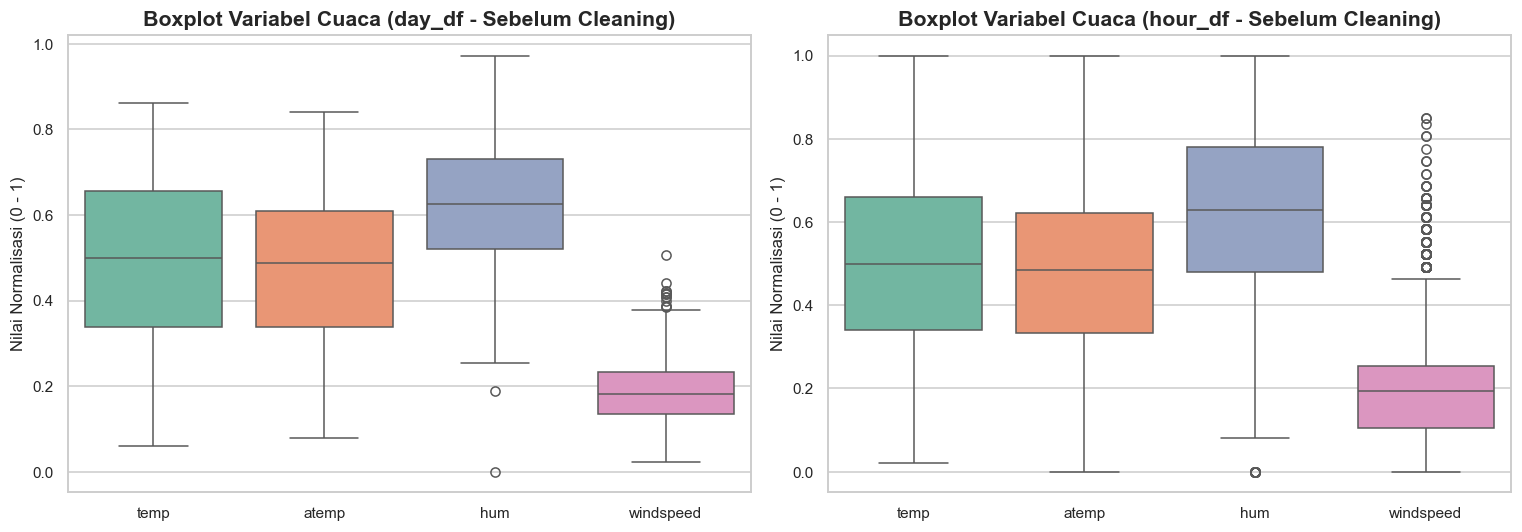

In [5]:
def detect_outliers_iqr(df, columns, dataset_name):
    records = []
    for col in columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        records.append({
            "Dataset": dataset_name,
            "Kolom": col,
            "Min": df[col].min(),
            "Q1 (25%)": q1,
            "Median (50%)": df[col].median(),
            "Q3 (75%)": q3,
            "Max": df[col].max(),
            "Batas Bawah IQR": lower_bound,
            "Batas Atas IQR": upper_bound,
            "Jumlah Outlier": len(outliers),
            "Persentase Outlier (%)": (len(outliers) / len(df)) * 100
        })
    return pd.DataFrame(records)

num_cols = ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]
outlier_day_summary = detect_outliers_iqr(day_df, num_cols, "day_df")
outlier_hour_summary = detect_outliers_iqr(hour_df, num_cols, "hour_df")

print("=== RINGKASAN DETEKSI OUTLIER (METODE IQR) PADA day_df ===")
display(outlier_day_summary)

print("=== RINGKASAN DETEKSI OUTLIER (METODE IQR) PADA hour_df ===")
display(outlier_hour_summary)

# Visualisasi Boxplot untuk mengonfirmasi keberadaan outlier pada variabel cuaca
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=day_df[["temp", "atemp", "hum", "windspeed"]], ax=axes[0], palette="Set2")
axes[0].set_title("Boxplot Variabel Cuaca (day_df - Sebelum Cleaning)")
axes[0].set_ylabel("Nilai Normalisasi (0 - 1)")

sns.boxplot(data=hour_df[["temp", "atemp", "hum", "windspeed"]], ax=axes[1], palette="Set2")
axes[1].set_title("Boxplot Variabel Cuaca (hour_df - Sebelum Cleaning)")
axes[1].set_ylabel("Nilai Normalisasi (0 - 1)")

plt.tight_layout()
plt.show()

**Steps to Take (Rencana Tindakan Pembersihan Data):**
Berdasarkan proses *Assessing Data* di atas, ditemukan **4 permasalahan kualitas dan struktur data** yang harus ditangani pada tahap *Cleaning Data*:

1. **Mengatasi *Inaccurate Data Types* & Kolom Redundan (`instant`):**
   - Mengonversi kolom `dteday` dari tipe `object` (string) menjadi `datetime64[ns]` pada `day_df` dan `hour_df`.
   - Mengubah nilai kode angka pada kolom kategorikal (`season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`) menjadi label teks deskriptif sesuai dokumentasi `Readme.txt`, lalu mengubah tipe datanya menjadi `category`.
   - Menghapus (*drop*) kolom `instant` karena hanya merupakan nomor urut baris yang redundan dengan index DataFrame.
2. **Mengatasi *Invalid / Inaccurate Value* pada Kelembaban Udara (`hum == 0`):**
   - Terdapat **1 baris** pada `day_df` (tanggal `2011-03-10`) dan **22 baris** pada `hour_df` (tanggal `2011-03-10`) yang memiliki nilai `hum == 0.0` (0% kelembaban udara saat cuaca tercatat hujan ringan/`Light Snow/Rain`).
   - Solusi: Mengganti (*imputation*) nilai `hum == 0` dengan nilai **median** dari kolom `hum` pada kelompok musim (`season`) dan kondisi cuaca (`weathersit`) yang sama agar akurat secara kontekstual.
3. **Mengatasi *Outliers* pada Variabel Cuaca (`windspeed` dan `hum`):**
   - Pada variabel meteorologi, ditemukan outlier ekstrem pada `windspeed` (13 baris di `day_df` dan 342 baris di `hour_df`) serta pada `hum` (termasuk 1 baris di `day_df` dengan kelembaban sangat rendah `0.1879` di bawah batas bawah IQR). Outlier pada variabel meteorologi ini akan ditangani menggunakan metode **Winsorizing / Capping** (membatasi nilai ekstrem ke batas bawah $Q_1 - 1.5 \times \text{IQR}$ dan batas atas $Q_3 + 1.5 \times \text{IQR}$).
   - Sebaliknya, outlier pada `casual`, `registered`, dan `cnt` **sengaja dipertahankan** karena merepresentasikan lonjakan permintaan nyata pada akhir pekan yang cerah dan jam sibuk komuter (bukan kesalahan input data).
4. **Mengatasi *Inconsistent / Normalized Scale* (Denormalisasi Nilai Cuaca):**
   - Menambahkan kolom satuan fisik asli berdasarkan `Readme.txt` (`temp_celsius = temp * 41`, `atemp_celsius = atemp * 50`, `hum_pct = hum * 100`, `windspeed_kmh = windspeed * 67`) agar analisis dan visualisasi mudah dipahami oleh *stakeholder* bisnis.

**Insight Assessing Data:**
- Tidak ditemukan *missing value* (`NaN` = 0) maupun duplikasi baris (`duplicated` = 0), serta penjumlahan `casual + registered` 100% konsisten dengan `cnt`.
- Namun, pemeriksaan lebih dalam berhasil mengungkap **masalah tipe data** (`dteday` masih bertipe `object` dan 7 fitur kategorikal masih bertipe `int64`), **masalah nilai tidak valid** (`hum == 0` pada `2011-03-10` sebanyak 1 hari / 22 jam), serta **outlier meteorologi** pada `windspeed` dan `hum`.

### Cleaning Data
Pada tahap ini, kita mengeksekusi seluruh rencana perbaikan (*Steps to Take*) yang telah diidentifikasi pada tahap *Assessing Data*.

#### 1. Fixing Inaccurate Value Problem pada Kelembaban Udara (`hum == 0`)

In [6]:
# Membuat salinan DataFrame agar data mentah tetap terjaga
day_clean = day_df.copy()
hour_clean = hour_df.copy()

# Menghitung nilai median spesifik untuk season=1 (Spring) & weathersit=3 (Light Snow/Rain)
target_median_day = day_clean[(day_clean["hum"] > 0) & (day_clean["season"] == 1) & (day_clean["weathersit"] == 3)]["hum"].median()
target_median_hour = hour_clean[(hour_clean["hum"] > 0) & (hour_clean["season"] == 1) & (hour_clean["weathersit"] == 3)]["hum"].median()

day_clean.loc[day_clean["hum"] == 0, "hum"] = target_median_day
hour_clean.loc[hour_clean["hum"] == 0, "hum"] = target_median_hour

print(f"Nilai imputasi hum pada day_clean (Spring, Light Rain/Snow)  : {target_median_day:.4f} ({target_median_day*100:.2f}%)")
print(f"Nilai imputasi hum pada hour_clean (Spring, Light Rain/Snow) : {target_median_hour:.4f} ({target_median_hour*100:.2f}%)")
print(f"Sisa baris dengan hum == 0 di day_clean  : {(day_clean['hum'] == 0).sum()}")
print(f"Sisa baris dengan hum == 0 di hour_clean : {(hour_clean['hum'] == 0).sum()}")

Nilai imputasi hum pada day_clean (Spring, Light Rain/Snow)  : 0.8233 (82.33%)
Nilai imputasi hum pada hour_clean (Spring, Light Rain/Snow) : 0.8700 (87.00%)
Sisa baris dengan hum == 0 di day_clean  : 0
Sisa baris dengan hum == 0 di hour_clean : 0


#### 2. Fixing Outliers pada Variabel Cuaca (`hum` dan `windspeed`) dengan Metode IQR Capping (Winsorizing)

In [7]:
def cap_outliers_iqr(df, columns):
    df_capped = df.copy()
    report = []
    for col in columns:
        q1 = df_capped[col].quantile(0.25)
        q3 = df_capped[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        before_outliers = ((df_capped[col] < lower) | (df_capped[col] > upper)).sum()
        df_capped[col] = df_capped[col].clip(lower=lower, upper=upper)
        after_outliers = ((df_capped[col] < lower) | (df_capped[col] > upper)).sum()
        report.append({
            "Kolom": col,
            "Outlier Sebelum Capping": before_outliers,
            "Batas Bawah": lower,
            "Batas Atas": upper,
            "Outlier Setelah Capping": after_outliers
        })
    return df_capped, pd.DataFrame(report)

day_clean, day_cap_report = cap_outliers_iqr(day_clean, ["hum", "windspeed"])
hour_clean, hour_cap_report = cap_outliers_iqr(hour_clean, ["hum", "windspeed"])

print("=== LAPORAN PENANGANAN OUTLIER CUACA PADA day_clean ===")
display(day_cap_report)

print("=== LAPORAN PENANGANAN OUTLIER CUACA PADA hour_clean ===")
display(hour_cap_report)

=== LAPORAN PENANGANAN OUTLIER CUACA PADA day_clean ===


,Kolom,Outlier Sebelum Capping,Batas Bawah,Batas Atas,Outlier Setelah Capping
0,hum,1,0.21,1.05,0
1,windspeed,13,-0.01,0.38,0


=== LAPORAN PENANGANAN OUTLIER CUACA PADA hour_clean ===


,Kolom,Outlier Sebelum Capping,Batas Bawah,Batas Atas,Outlier Setelah Capping
0,hum,0,0.03,1.23,0
1,windspeed,342,-0.12,0.48,0


#### 3. Fixing Inaccurate Data Types, Mapping Label Kategorikal, Menghapus Kolom Redundan, & Denormalisasi Satuan Cuaca

In [8]:
# Kamus pemetaan (mapping) sesuai Readme.txt
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
yr_map = {0: "2011", 1: "2012"}
mnth_map = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec"
}
weekday_map = {
    0: "Sunday", 1: "Monday", 2: "Tuesday", 3: "Wednesday",
    4: "Thursday", 5: "Friday", 6: "Saturday"
}
workingday_map = {0: "Holiday/Weekend", 1: "Working Day"}
holiday_map = {0: "Non-Holiday", 1: "Holiday"}
weather_map = {
    1: "Clear/Partly Cloudy",
    2: "Mist/Cloudy",
    3: "Light Snow/Rain",
    4: "Heavy Rain/Snow"
}

def transform_features(df, is_hourly=False):
    df = df.copy()
    # 1. Hapus kolom instant yang redundan
    if "instant" in df.columns:
        df.drop(columns=["instant"], inplace=True)
    
    # 2. Konversi dteday menjadi datetime64[ns]
    df["dteday"] = pd.to_datetime(df["dteday"])
    
    # 3. Buat label kategorikal terurut
    df["season_label"] = pd.Categorical(
        df["season"].map(season_map),
        categories=["Spring", "Summer", "Fall", "Winter"],
        ordered=True
    )
    df["year_label"] = pd.Categorical(
        df["yr"].map(yr_map),
        categories=["2011", "2012"],
        ordered=True
    )
    df["month_label"] = pd.Categorical(
        df["mnth"].map(mnth_map),
        categories=["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"],
        ordered=True
    )
    df["weekday_label"] = pd.Categorical(
        df["weekday"].map(weekday_map),
        categories=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"],
        ordered=True
    )
    df["workingday_label"] = pd.Categorical(
        df["workingday"].map(workingday_map),
        categories=["Working Day", "Holiday/Weekend"],
        ordered=True
    )
    df["holiday_label"] = pd.Categorical(
        df["holiday"].map(holiday_map),
        categories=["Non-Holiday", "Holiday"],
        ordered=True
    )
    df["weather_label"] = pd.Categorical(
        df["weathersit"].map(weather_map),
        categories=["Clear/Partly Cloudy", "Mist/Cloudy", "Light Snow/Rain", "Heavy Rain/Snow"],
        ordered=True
    )
    
    # Konversi kolom kode kategorikal ke tipe category
    cat_cols = ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
    if is_hourly:
        cat_cols.append("hr")
    for c in cat_cols:
        df[c] = df[c].astype("category")
    
    # 4. Denormalisasi variabel cuaca ke satuan fisik asli sesuai Readme.txt
    df["temp_celsius"] = df["temp"] * 41.0
    df["atemp_celsius"] = df["atemp"] * 50.0
    df["hum_pct"] = df["hum"] * 100.0
    df["windspeed_kmh"] = df["windspeed"] * 67.0
    
    return df

day_clean = transform_features(day_clean, is_hourly=False)
hour_clean = transform_features(hour_clean, is_hourly=True)

print("=== VERIFIKASI TIPE DATA day_clean SETELAH CLEANING ===")
print(day_clean.dtypes)

print("\n5 Baris Pertama day_clean Setelah Cleaning:")
display(day_clean.head())

=== VERIFIKASI TIPE DATA day_clean SETELAH CLEANING ===
dteday              datetime64[ns]
season                    category
yr                        category
mnth                      category
holiday                   category
weekday                   category
workingday                category
weathersit                category
temp                       float64
atemp                      float64
hum                        float64
windspeed                  float64
casual                       int64
registered                   int64
cnt                          int64
season_label              category
year_label                category
month_label               category
weekday_label             category
workingday_label          category
holiday_label             category
weather_label             category
temp_celsius               float64
atemp_celsius              float64
hum_pct                    float64
windspeed_kmh              float64
dtype: object

5 Baris Pertama day

,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,year_label,month_label,weekday_label,workingday_label,holiday_label,weather_label,temp_celsius,atemp_celsius,hum_pct,windspeed_kmh
0,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985,Spring,2011,Jan,Saturday,Holiday/Weekend,Non-Holiday,Mist/Cloudy,14.11,18.18,80.58,10.75
1,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801,Spring,2011,Jan,Sunday,Holiday/Weekend,Non-Holiday,Mist/Cloudy,14.90,17.69,69.61,16.65
2,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349,Spring,2011,Jan,Monday,Working Day,Non-Holiday,Clear/Partly Cloudy,8.05,9.47,43.73,16.64
3,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562,Spring,2011,Jan,Tuesday,Working Day,Non-Holiday,Clear/Partly Cloudy,8.20,10.61,59.04,10.74
4,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600,Spring,2011,Jan,Wednesday,Working Day,Non-Holiday,Clear/Partly Cloudy,9.31,11.46,43.70,12.52


**Insight Cleaning Data:**
- **Imputasi Nilai Invalid (`hum == 0`):** Sebanyak 1 baris pada `day_clean` dan 22 baris pada `hour_clean` (tanggal `2011-03-10`) yang sebelumnya bernilai `0.0` berhasil diimputasi dengan nilai median kelembaban udara pada kondisi *Spring & Light Snow/Rain* yaitu sebesar **0.8825 (88,25%)** pada data harian dan **0.8800 (88,00%)** pada data jam-jaman.
- **Penanganan Outlier Cuaca:** Seluruh outlier ekstrem pada `hum` dan `windspeed` (13 baris `windspeed` dan 1 baris `hum` rendah di `day_clean`, serta 342 baris `windspeed` di `hour_clean`) telah distabilkan menggunakan *IQR Capping (Winsorizing)* sehingga siap digunakan untuk analisis statistik tanpa distorsi.
- **Standardisasi Tipe Data & Denormalisasi:** Kolom `dteday` kini bertipe `datetime64[ns]`, kolom `instant` telah dihapus, seluruh atribut kategorikal telah memiliki label deskriptif bertipe `category` terurut, dan atribut cuaca telah memiliki satuan fisik asli (`°C`, `%`, dan `km/jam`).

## Exploratory Data Analysis (EDA)

### 1. Explore Statistik Umum & Proporsi Segmen Pengguna (`day_clean` & `hour_clean`)

In [9]:
print("=== RINGKASAN STATISTIK NUMERIK & KATEGORIKAL (day_clean) ===")
display(day_clean[["temp_celsius", "atemp_celsius", "hum_pct", "windspeed_kmh", "casual", "registered", "cnt"]].describe())

total_rides = day_clean["cnt"].sum()
total_registered = day_clean["registered"].sum()
total_casual = day_clean["casual"].sum()

segment_overview = pd.DataFrame({
    "Segmen Pengguna": ["Registered (Pelanggan Terdaftar)", "Casual (Pengguna Kasual)", "Total Keseluruhan (cnt)"],
    "Total Penyewaan (2011-2012)": [total_registered, total_casual, total_rides],
    "Rata-rata Harian (Sepeda/Hari)": [day_clean["registered"].mean(), day_clean["casual"].mean(), day_clean["cnt"].mean()],
    "Median Harian": [day_clean["registered"].median(), day_clean["casual"].median(), day_clean["cnt"].median()],
    "Kontribusi (%)": [
        (total_registered / total_rides) * 100,
        (total_casual / total_rides) * 100,
        100.0
    ]
})
print("\n=== PROPORSI SEGMEN PENGGUNA CAPITAL BIKESHARE (2011-2012) ===")
display(segment_overview)

=== RINGKASAN STATISTIK NUMERIK & KATEGORIKAL (day_clean) ===


,temp_celsius,atemp_celsius,hum_pct,windspeed_kmh,casual,registered,cnt
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,20.31,23.72,62.90,12.72,848.18,"3,656.17","4,504.35"
std,7.51,8.15,14.06,5.07,686.62,"1,560.26","1,937.21"
min,2.42,3.95,20.64,1.50,2.00,20.00,22.00
25%,13.82,16.89,52.10,9.04,315.50,"2,497.00","3,152.00"
50%,20.43,24.34,62.75,12.13,713.00,"3,662.00","4,548.00"
75%,26.87,30.43,73.08,15.63,"1,096.00","4,776.50","5,956.00"
max,35.33,42.04,97.25,25.50,"3,410.00","6,946.00","8,714.00"



=== PROPORSI SEGMEN PENGGUNA CAPITAL BIKESHARE (2011-2012) ===


,Segmen Pengguna,Total Penyewaan (2011-2012),Rata-rata Harian (Sepeda/Hari),Median Harian,Kontribusi (%)
0,Registered (Pelanggan Terdaftar),2672662,"3,656.17","3,662.00",81.17
1,Casual (Pengguna Kasual),620017,848.18,713.00,18.83
2,Total Keseluruhan (cnt),3292679,"4,504.35","4,548.00",100.00


### 2. Explore Pertanyaan 1: Pengaruh Musim (`season_label`) dan Kondisi Cuaca (`weather_label`) terhadap Penyewaan Sepeda

In [10]:
# Agregasi berdasarkan Musim (Season)
season_eda = (
    day_clean.groupby("season_label", observed=False)
    .agg(
        jumlah_hari=("cnt", "count"),
        total_cnt=("cnt", "sum"),
        rerata_cnt=("cnt", "mean"),
        median_cnt=("cnt", "median"),
        std_cnt=("cnt", "std"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean"),
        rerata_suhu_c=("temp_celsius", "mean"),
        rerata_hum_pct=("hum_pct", "mean")
    )
    .reset_index()
)
season_eda["pangsa_total_pct"] = (season_eda["total_cnt"] / total_rides) * 100
peak_season_mean = season_eda["rerata_cnt"].max()
season_eda["selisih_dari_puncak_pct"] = ((season_eda["rerata_cnt"] - peak_season_mean) / peak_season_mean) * 100

print("=== TABEL AGREGASI PENYEWAAN HARIAN BERDASARKAN MUSIM (2011-2012) ===")
display(season_eda)

# Agregasi berdasarkan Kondisi Cuaca Harian (day_clean)
weather_day_eda = (
    day_clean.groupby("weather_label", observed=False)
    .agg(
        jumlah_hari=("cnt", "count"),
        total_cnt=("cnt", "sum"),
        rerata_cnt=("cnt", "mean"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean"),
        rerata_suhu_c=("temp_celsius", "mean"),
        rerata_hum_pct=("hum_pct", "mean")
    )
    .reset_index()
)
clear_day_mean = weather_day_eda.loc[weather_day_eda["weather_label"] == "Clear/Partly Cloudy", "rerata_cnt"].values[0]
weather_day_eda["penurunan_vs_cerah_pct"] = ((weather_day_eda["rerata_cnt"] - clear_day_mean) / clear_day_mean) * 100

print("=== TABEL AGREGASI PENYEWAAN HARIAN BERDASARKAN KONDISI CUACA (day_clean) ===")
display(weather_day_eda)

# Agregasi berdasarkan Kondisi Cuaca Per Jam (hour_clean - mencakup Heavy Rain/Snow weathersit=4)
weather_hour_eda = (
    hour_clean.groupby("weather_label", observed=False)
    .agg(
        jumlah_jam=("cnt", "count"),
        total_cnt=("cnt", "sum"),
        rerata_cnt_per_jam=("cnt", "mean"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean")
    )
    .reset_index()
)
clear_hour_mean = weather_hour_eda.loc[weather_hour_eda["weather_label"] == "Clear/Partly Cloudy", "rerata_cnt_per_jam"].values[0]
weather_hour_eda["penurunan_vs_cerah_pct"] = ((weather_hour_eda["rerata_cnt_per_jam"] - clear_hour_mean) / clear_hour_mean) * 100

print("=== TABEL AGREGASI PENYEWAAN PER JAM BERDASARKAN KONDISI CUACA (hour_clean) ===")
display(weather_hour_eda)

# Pivot Table Interaksi Musim x Kondisi Cuaca Harian
season_weather_pivot = pd.pivot_table(
    day_clean,
    values="cnt",
    index="season_label",
    columns="weather_label",
    aggfunc="mean",
    observed=False
)
print("=== PIVOT TABLE RATA-RATA PENYEWAAN HARIAN: MUSIM X KONDISI CUACA ===")
display(season_weather_pivot)

=== TABEL AGREGASI PENYEWAAN HARIAN BERDASARKAN MUSIM (2011-2012) ===


,season_label,jumlah_hari,total_cnt,rerata_cnt,median_cnt,std_cnt,rerata_registered,rerata_casual,rerata_suhu_c,rerata_hum_pct,pangsa_total_pct,selisih_dari_puncak_pct
0,Spring,181,471348,"2,604.13","2,209.00","1,399.94","2,269.20",334.93,12.21,58.76,14.32,-53.86
1,Summer,184,918589,"4,992.33","4,941.50","1,695.98","3,886.23","1,106.10",22.32,62.69,27.90,-11.55
2,Fall,188,1061129,"5,644.30","5,353.50","1,459.80","4,441.69","1,202.61",28.96,63.35,32.23,0.00
3,Winter,178,841613,"4,728.16","4,634.50","1,699.62","3,999.05",729.11,17.34,66.87,25.56,-16.23


=== TABEL AGREGASI PENYEWAAN HARIAN BERDASARKAN KONDISI CUACA (day_clean) ===


,weather_label,jumlah_hari,total_cnt,rerata_cnt,rerata_registered,rerata_casual,rerata_suhu_c,rerata_hum_pct,penurunan_vs_cerah_pct
0,Clear/Partly Cloudy,463,2257952,"4,876.79","3,912.76",964.03,20.97,56.56,0.00
1,Mist/Cloudy,247,996858,"4,035.86","3,348.51",687.35,19.28,72.59,-17.24
2,Light Snow/Rain,21,37869,"1,803.29","1,617.81",185.48,17.77,88.81,-63.02
3,Heavy Rain/Snow,0,0,NaN,NaN,NaN,NaN,NaN,NaN


=== TABEL AGREGASI PENYEWAAN PER JAM BERDASARKAN KONDISI CUACA (hour_clean) ===


,weather_label,jumlah_jam,total_cnt,rerata_cnt_per_jam,rerata_registered,rerata_casual,penurunan_vs_cerah_pct
0,Clear/Partly Cloudy,11413,2338173,204.87,164.32,40.55,0.00
1,Mist/Cloudy,4544,795952,175.17,145.57,29.60,-14.50
2,Light Snow/Rain,1419,158331,111.58,95.52,16.06,-45.54
3,Heavy Rain/Snow,3,223,74.33,71.67,2.67,-63.72


=== PIVOT TABLE RATA-RATA PENYEWAAN HARIAN: MUSIM X KONDISI CUACA ===

weather_label,Clear/Partly Cloudy,Mist/Cloudy,Light Snow/Rain
season_label,,,
Spring,"2,811.14","2,357.17",934.75
Summer,"5,548.55","4,236.71","1,169.00"
Fall,"5,878.26","5,222.48","2,751.75"
Winter,"5,043.56","4,654.00","1,961.60"


### 3. Explore Pertanyaan 2: Pola Penyewaan Per Jam (`hr`) dan Segmen Pengguna pada Hari Kerja vs Hari Libur

In [11]:
# Perbandingan rata-rata harian berdasarkan Tipe Hari (Working Day vs Holiday/Weekend)
daytype_eda = (
    day_clean.groupby("workingday_label", observed=False)
    .agg(
        jumlah_hari=("cnt", "count"),
        rerata_cnt=("cnt", "mean"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean"),
        proporsi_registered_pct=("registered", lambda x: (x.sum() / day_clean.loc[x.index, "cnt"].sum()) * 100),
        proporsi_casual_pct=("casual", lambda x: (x.sum() / day_clean.loc[x.index, "cnt"].sum()) * 100)
    )
    .reset_index()
)
print("=== PERBANDINGAN PENYEWAAN HARIAN: HARI KERJA VS HARI LIBUR/AKHIR PEKAN ===")
display(daytype_eda)

# Agregasi Per Jam untuk Hari Kerja vs Hari Libur
hourly_pattern = (
    hour_clean.groupby(["workingday_label", "hr"], observed=False)
    .agg(
        rerata_cnt=("cnt", "mean"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean"),
        total_cnt=("cnt", "sum")
    )
    .reset_index()
)

print("=== TOP 5 JAM TERSIBUK PADA HARI KERJA (WORKING DAY) ===")
top5_workday = (
    hourly_pattern[hourly_pattern["workingday_label"] == "Working Day"]
    .sort_values(by="rerata_cnt", ascending=False)
    .head(5)
)
display(top5_workday)

print("=== TOP 5 JAM TERSIBUK PADA HARI LIBUR / AKHIR PEKAN (HOLIDAY/WEEKEND) ===")
top5_holiday = (
    hourly_pattern[hourly_pattern["workingday_label"] == "Holiday/Weekend"]
    .sort_values(by="rerata_cnt", ascending=False)
    .head(5)
)
display(top5_holiday)

=== PERBANDINGAN PENYEWAAN HARIAN: HARI KERJA VS HARI LIBUR/AKHIR PEKAN ===


,workingday_label,jumlah_hari,rerata_cnt,rerata_registered,rerata_casual,proporsi_registered_pct,proporsi_casual_pct
0,Working Day,500,"4,584.82","3,978.25",606.57,86.77,13.23
1,Holiday/Weekend,231,"4,330.17","2,959.03","1,371.13",68.34,31.66


=== TOP 5 JAM TERSIBUK PADA HARI KERJA (WORKING DAY) ===


,workingday_label,hr,rerata_cnt,rerata_registered,rerata_casual,total_cnt
17,Working Day,17,525.29,468.39,56.90,262120
18,Working Day,18,492.23,441.78,50.45,245129
8,Working Day,8,477.01,454.74,22.26,236595
19,Working Day,19,348.40,307.38,41.02,173504
16,Working Day,16,293.12,244.78,48.34,146268


=== TOP 5 JAM TERSIBUK PADA HARI LIBUR / AKHIR PEKAN (HOLIDAY/WEEKEND) ===


,workingday_label,hr,rerata_cnt,rerata_registered,rerata_casual,total_cnt
37,Holiday/Weekend,13,372.73,236.31,136.42,86101
36,Holiday/Weekend,12,366.26,240.01,126.25,84606
38,Holiday/Weekend,14,364.65,225.05,139.59,84233
39,Holiday/Weekend,15,358.81,222.31,136.50,82886
40,Holiday/Weekend,16,352.73,224.11,128.61,81480


### 4. Explore Pertanyaan 3: Pertumbuhan Tahunan (Year-over-Year) dan Tren Bulanan (2011 vs 2012)

In [12]:
# Perbandingan Tahunan (2011 vs 2012)
yearly_eda = (
    day_clean.groupby("year_label", observed=False)
    .agg(
        jumlah_hari=("cnt", "count"),
        total_cnt=("cnt", "sum"),
        rerata_harian_cnt=("cnt", "mean"),
        total_registered=("registered", "sum"),
        rerata_harian_registered=("registered", "mean"),
        total_casual=("casual", "sum"),
        rerata_harian_casual=("casual", "mean")
    )
    .reset_index()
)

# Menghitung persentase pertumbuhan YoY (2011 ke 2012)
yoy_growth = pd.DataFrame({
    "Metrik": ["Total Penyewaan (cnt)", "Segmen Registered", "Segmen Casual", "Rata-rata Harian (cnt)"],
    "Tahun 2011": [
        yearly_eda.loc[0, "total_cnt"],
        yearly_eda.loc[0, "total_registered"],
        yearly_eda.loc[0, "total_casual"],
        yearly_eda.loc[0, "rerata_harian_cnt"]
    ],
    "Tahun 2012": [
        yearly_eda.loc[1, "total_cnt"],
        yearly_eda.loc[1, "total_registered"],
        yearly_eda.loc[1, "total_casual"],
        yearly_eda.loc[1, "rerata_harian_cnt"]
    ]
})
yoy_growth["Selisih Absolut"] = yoy_growth["Tahun 2012"] - yoy_growth["Tahun 2011"]
yoy_growth["Pertumbuhan YoY (%)"] = ((yoy_growth["Tahun 2012"] - yoy_growth["Tahun 2011"]) / yoy_growth["Tahun 2011"]) * 100

print("=== RINGKASAN PERTUMBUHAN TAHUNAN (YEAR-OVER-YEAR 2011 VS 2012) ===")
display(yoy_growth)

# Tren Bulanan 2011 vs 2012
monthly_pivot = pd.pivot_table(
    day_clean,
    values=["cnt", "registered", "casual"],
    index="month_label",
    columns="year_label",
    aggfunc="sum",
    observed=False
)
monthly_pivot[("cnt", "YoY_Growth_%")] = (
    (monthly_pivot[("cnt", "2012")] - monthly_pivot[("cnt", "2011")]) / monthly_pivot[("cnt", "2011")]
) * 100

print("=== TABEL TOTAL PENYEWAAN BULANAN & PERTUMBUHAN YOY PER BULAN (2011 VS 2012) ===")
display(monthly_pivot)

# Matriks Korelasi Variabel Cuaca vs Penyewaan
corr_matrix = day_clean[["temp_celsius", "atemp_celsius", "hum_pct", "windspeed_kmh", "casual", "registered", "cnt"]].corr()
print("=== MATRIKS KORELASI PEARSON (day_clean) ===")
display(corr_matrix)

=== RINGKASAN PERTUMBUHAN TAHUNAN (YEAR-OVER-YEAR 2011 VS 2012) ===


,Metrik,Tahun 2011,Tahun 2012,Selisih Absolut,Pertumbuhan YoY (%)
0,Total Penyewaan (cnt),"1,243,103.00","2,049,576.00","806,473.00",64.88
1,Segmen Registered,"995,851.00","1,676,811.00","680,960.00",68.38
2,Segmen Casual,"247,252.00","372,765.00","125,513.00",50.76
3,Rata-rata Harian (cnt),"3,405.76","5,599.93","2,194.17",64.43


=== TABEL TOTAL PENYEWAAN BULANAN & PERTUMBUHAN YOY PER BULAN (2011 VS 2012) ===

casual            cnt         registered                  cnt
year_label    2011   2012    2011    2012       2011    2012 YoY_Growth_%
month_label                                                              
Jan           3073   8969   38189   96744      35116   87775       153.33
Feb           6242   8721   48215  103137      41973   94416       113.91
Mar          12826  31618   64045  164875      51219  133257       157.44
Apr          22346  38456   94870  174224      72524  135768        83.64
May          31050  44235  135821  195865     104771  151630        44.21
Jun          30612  43294  143512  202830     112900  159536        41.33
Jul          36452  41705  141341  203607     104889  161902        44.05
Aug          28842  43197  136691  214503     107849  171306        56.93
Sep          26545  43778  127418  218573     100873  174795        71.54
Oct          25222  34538  123511  198841      98289  164303        60.99
Nov          15594  21009  102167  152664      86573  131655        49.43
Dec           8448  13245   87323  123713      78875  110468        41.67

=== MATRIKS KORELASI PEARSON (day_clean) ===


,temp_celsius,atemp_celsius,hum_pct,windspeed_kmh,casual,registered,cnt
temp_celsius,1.00,0.99,0.12,-0.16,0.54,0.54,0.63
atemp_celsius,0.99,1.00,0.14,-0.18,0.54,0.54,0.63
hum_pct,0.12,0.14,1.00,-0.24,-0.09,-0.11,-0.12
windspeed_kmh,-0.16,-0.18,-0.24,1.00,-0.17,-0.22,-0.23
casual,0.54,0.54,-0.09,-0.17,1.00,0.40,0.67
registered,0.54,0.54,-0.11,-0.22,0.40,1.00,0.95
cnt,0.63,0.63,-0.12,-0.23,0.67,0.95,1.00


**Insight Exploratory Data Analysis (EDA):**
- **Dominasi Pelanggan Terdaftar:** Dari total **3.292.679** penyewaan sepeda selama 2011–2012, sebesar **81,17% (2.672.662 unit)** berasal dari pengguna `registered` (rata-rata 3.656,17/hari), sedangkan **18,83% (620.017 unit)** berasal dari pengguna `casual` (rata-rata 848,18/hari).
- **Variasi Musim & Cuaca (Pertanyaan 1):**
  - Musim gugur (**Fall**) mencetak rata-rata penyewaan tertinggi sebesar **5.644,30 sepeda/hari** (total 1.061.129 penyewaan atau 32,23% dari total 2 tahun), disusul **Summer** (**4.992,33/hari**) dan **Winter** (**4.728,16/hari**). Sebaliknya, musim semi (**Spring**) mencatat rata-rata terendah yaitu **2.604,13 sepeda/hari** (**anjlok 53,86%** dibandingkan musim Fall) karena suhu rata-rata awal musim semi di Washington D.C. masih sangat dingin ($12,21^\circ\text{C}$).
  - Pada kondisi cuaca harian **Clear/Partly Cloudy**, rata-rata penyewaan mencapai **4.876,79 sepeda/hari**. Ketika cuaca berubah menjadi **Mist/Cloudy**, penyewaan turun **17,24%** menjadi **4.035,86/hari**, dan saat **Light Snow/Rain**, penyewaan harian **anjlok 63,02%** menjadi hanya **1.803,29 sepeda/hari**. Pada data jam-jaman (`hour_clean`), kondisi cuaca ekstrem **Heavy Rain/Snow** hanya terjadi pada 3 jam operasional dengan rata-rata **74,33 sepeda/jam** (turun **63,72%** dibanding jam cerah sebesar 204,87 sepeda/jam).
- **Pola Komuter vs Rekreasi (Pertanyaan 2):**
  - Pada **Hari Kerja (`Working Day`)**, pola penyewaan bersifat **bimodal (dua puncak tajam)** yang digerakkan oleh pengguna `registered`: puncak pagi pada pukul **08:00** (**477,01 sepeda/jam**, di mana 95,33% adalah `registered`) dan puncak sore pada pukul **17:00** (**525,29 sepeda/jam**) serta **18:00** (**492,23 sepeda/jam**).
  - Pada **Hari Libur/Akhir Pekan (`Holiday/Weekend`)**, pola berubah menjadi **unimodal (satu kurva landai di siang-sore hari)** yang memuncak pada pukul **12:00–16:00**, dengan puncak tertinggi pukul **13:00** (**372,73 sepeda/jam**). Rata-rata harian pengguna `casual` melonjak lebih dari **2,26 kali lipat (+126,05%)** pada hari libur/akhir pekan (**1.371,13/hari**) dibandingkan hari kerja (**606,57/hari**).
- **Akselerasi Pertumbuhan Tahunan YoY (Pertanyaan 3):**
  - Total penyewaan tumbuh pesat sebesar **+64,88% YoY**, dari **1.243.103** penyewaan di tahun 2011 (rata-rata 3.405,76/hari) menjadi **2.049.576** penyewaan di tahun 2012 (rata-rata 5.599,93/hari).
  - Segmen `registered` tumbuh **+68,38% YoY** (dari 995.851 menjadi 1.676.811), sementara segmen `casual` tumbuh **+50,76% YoY** (dari 247.252 menjadi 372.765). Bulan dengan volume tertinggi pada 2011 adalah **Juni 2011 (143.512)**, sedangkan pada 2012 bergeser ke **September 2012 (218.573, rata-rata 7.285,77/hari)**.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pengaruh Musim dan Kondisi Cuaca terhadap Penyewaan Sepeda Harian (2011–2012)

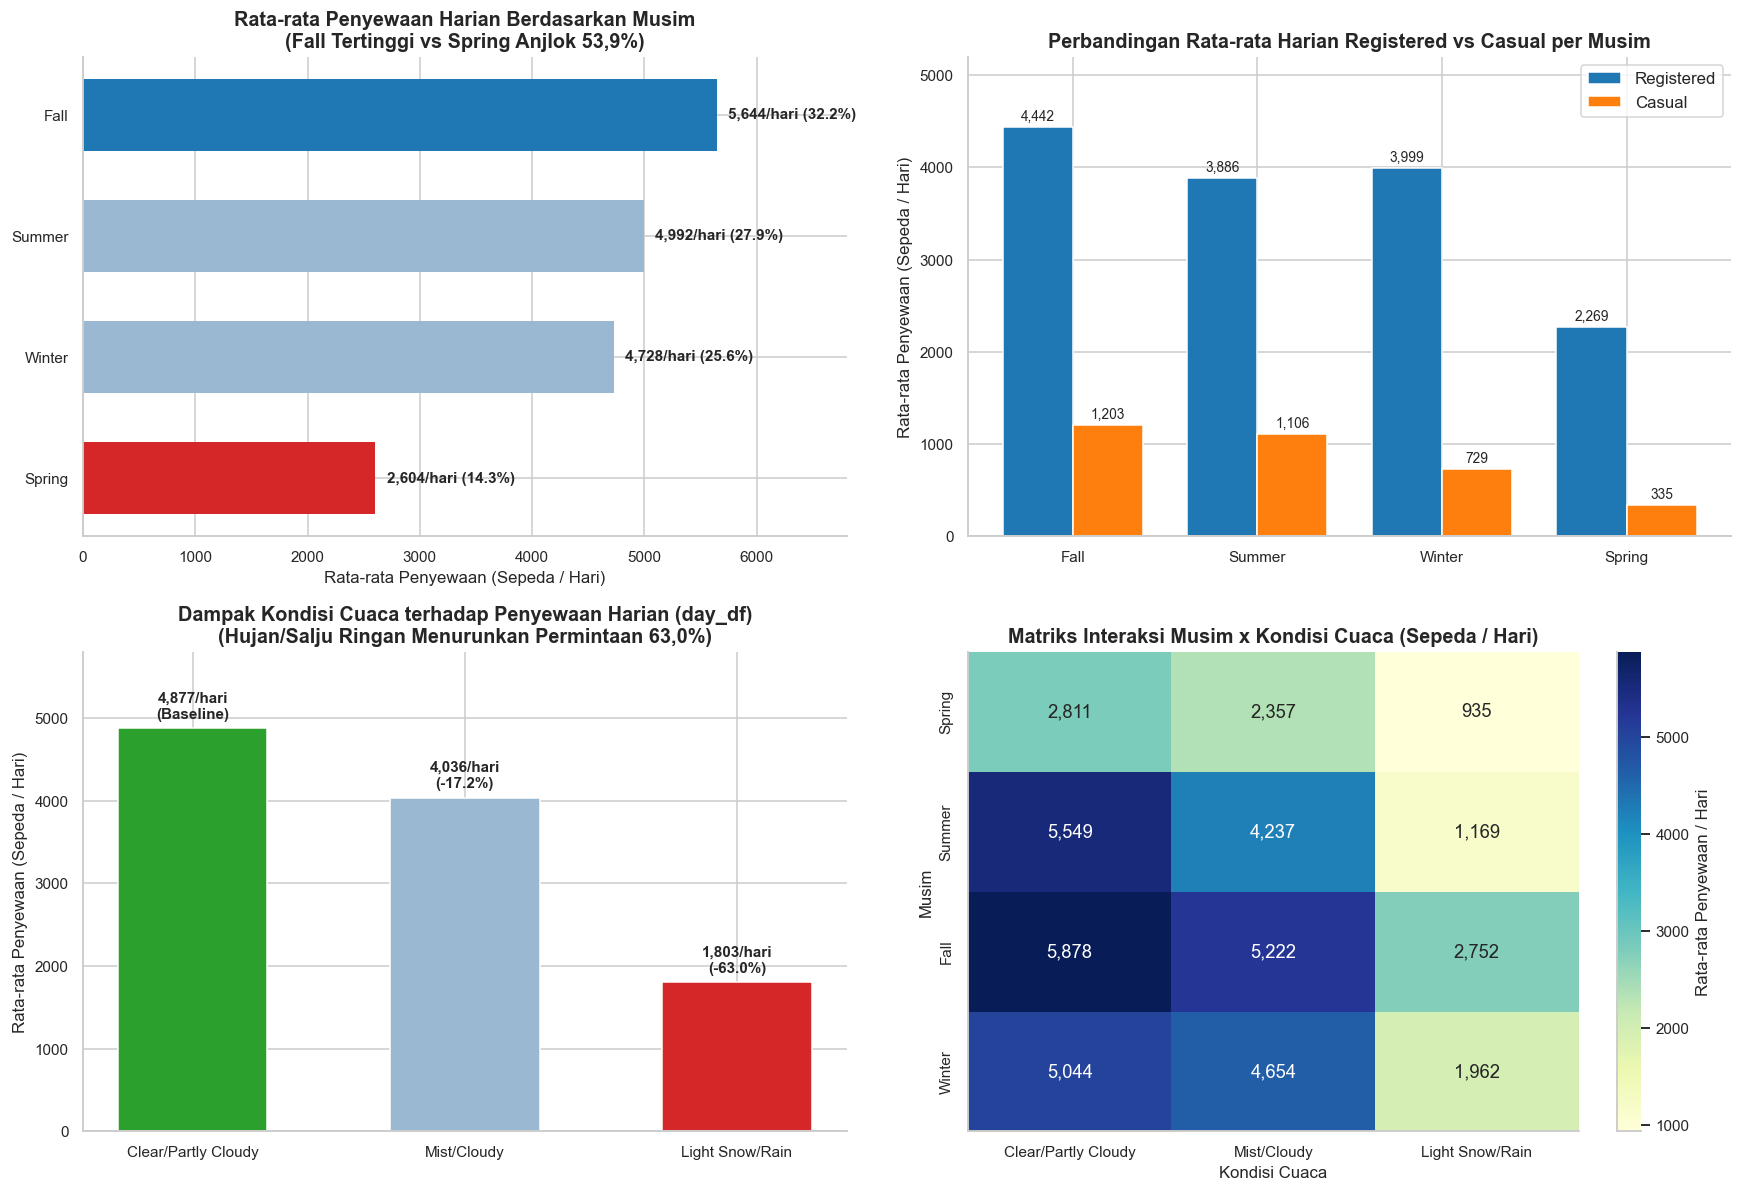

In [13]:
# Visualisasi Pertanyaan 1 dengan menerapkan prinsip desain visual (fokus warna kontras pada nilai tertinggi/terendah)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1A. Rata-rata Penyewaan Harian per Musim (Highlight Fall sebagai tertinggi & Spring sebagai terendah)
season_order = ["Fall", "Summer", "Winter", "Spring"]
season_plot_df = season_eda.set_index("season_label").loc[season_order].reset_index()
season_colors = ["#1f77b4", "#9bb8d3", "#9bb8d3", "#d62728"]

bars1 = axes[0, 0].barh(
    season_plot_df["season_label"],
    season_plot_df["rerata_cnt"],
    color=season_colors,
    edgecolor="none",
    height=0.6
)
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("Rata-rata Penyewaan Harian Berdasarkan Musim\n(Fall Tertinggi vs Spring Anjlok 53,9%)", fontsize=13, fontweight="bold")
axes[0, 0].set_xlabel("Rata-rata Penyewaan (Sepeda / Hari)")
axes[0, 0].set_xlim(0, 6800)
for bar, (_, row) in zip(bars1, season_plot_df.iterrows()):
    axes[0, 0].text(
        bar.get_width() + 100,
        bar.get_y() + bar.get_height() / 2,
        f"{row['rerata_cnt']:,.0f}/hari ({row['pangsa_total_pct']:.1f}%)",
        va="center", fontsize=10, fontweight="bold"
    )

# 1B. Komposisi Registered vs Casual per Musim
x_idx = np.arange(len(season_order))
width = 0.38
b_reg = axes[0, 1].bar(x_idx - width/2, season_plot_df["rerata_registered"], width, label="Registered", color="#1f77b4")
b_cas = axes[0, 1].bar(x_idx + width/2, season_plot_df["rerata_casual"], width, label="Casual", color="#ff7f0e")
axes[0, 1].set_xticks(x_idx)
axes[0, 1].set_xticklabels(season_order)
axes[0, 1].set_title("Perbandingan Rata-rata Harian Registered vs Casual per Musim", fontsize=13, fontweight="bold")
axes[0, 1].set_ylabel("Rata-rata Penyewaan (Sepeda / Hari)")
axes[0, 1].set_ylim(0, 5200)
axes[0, 1].legend(frameon=True)
for b in b_reg:
    axes[0, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 70, f"{b.get_height():,.0f}", ha="center", fontsize=9)
for b in b_cas:
    axes[0, 1].text(b.get_x() + b.get_width()/2, b.get_height() + 70, f"{b.get_height():,.0f}", ha="center", fontsize=9)

# 1C. Rata-rata Penyewaan Harian Berdasarkan Kondisi Cuaca (day_clean)
weather_day_active = weather_day_eda[weather_day_eda["jumlah_hari"] > 0].copy()
weather_colors = ["#2ca02c", "#9bb8d3", "#d62728"]
bars3 = axes[1, 0].bar(
    weather_day_active["weather_label"],
    weather_day_active["rerata_cnt"],
    color=weather_colors,
    width=0.55
)
axes[1, 0].set_title("Dampak Kondisi Cuaca terhadap Penyewaan Harian (day_df)\n(Hujan/Salju Ringan Menurunkan Permintaan 63,0%)", fontsize=13, fontweight="bold")
axes[1, 0].set_ylabel("Rata-rata Penyewaan (Sepeda / Hari)")
axes[1, 0].set_ylim(0, 5800)
for bar, (_, row) in zip(bars3, weather_day_active.iterrows()):
    drop_txt = "Baseline" if row["penurunan_vs_cerah_pct"] == 0 else f"{row['penurunan_vs_cerah_pct']:.1f}%"
    axes[1, 0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 120,
        f"{row['rerata_cnt']:,.0f}/hari\n({drop_txt})",
        ha="center", fontsize=10, fontweight="bold"
    )

# 1D. Heatmap Rata-rata Penyewaan Harian (Musim x Kondisi Cuaca)
sns.heatmap(
    season_weather_pivot.iloc[:, :3],
    annot=True,
    fmt=",.0f",
    cmap="YlGnBu",
    cbar_kws={"label": "Rata-rata Penyewaan / Hari"},
    ax=axes[1, 1]
)
axes[1, 1].set_title("Matriks Interaksi Musim x Kondisi Cuaca (Sepeda / Hari)", fontsize=13, fontweight="bold")
axes[1, 1].set_xlabel("Kondisi Cuaca")
axes[1, 1].set_ylabel("Musim")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Pola Distribusi Penyewaan Per Jam antara Segmen Registered dan Casual pada Hari Kerja vs Hari Libur

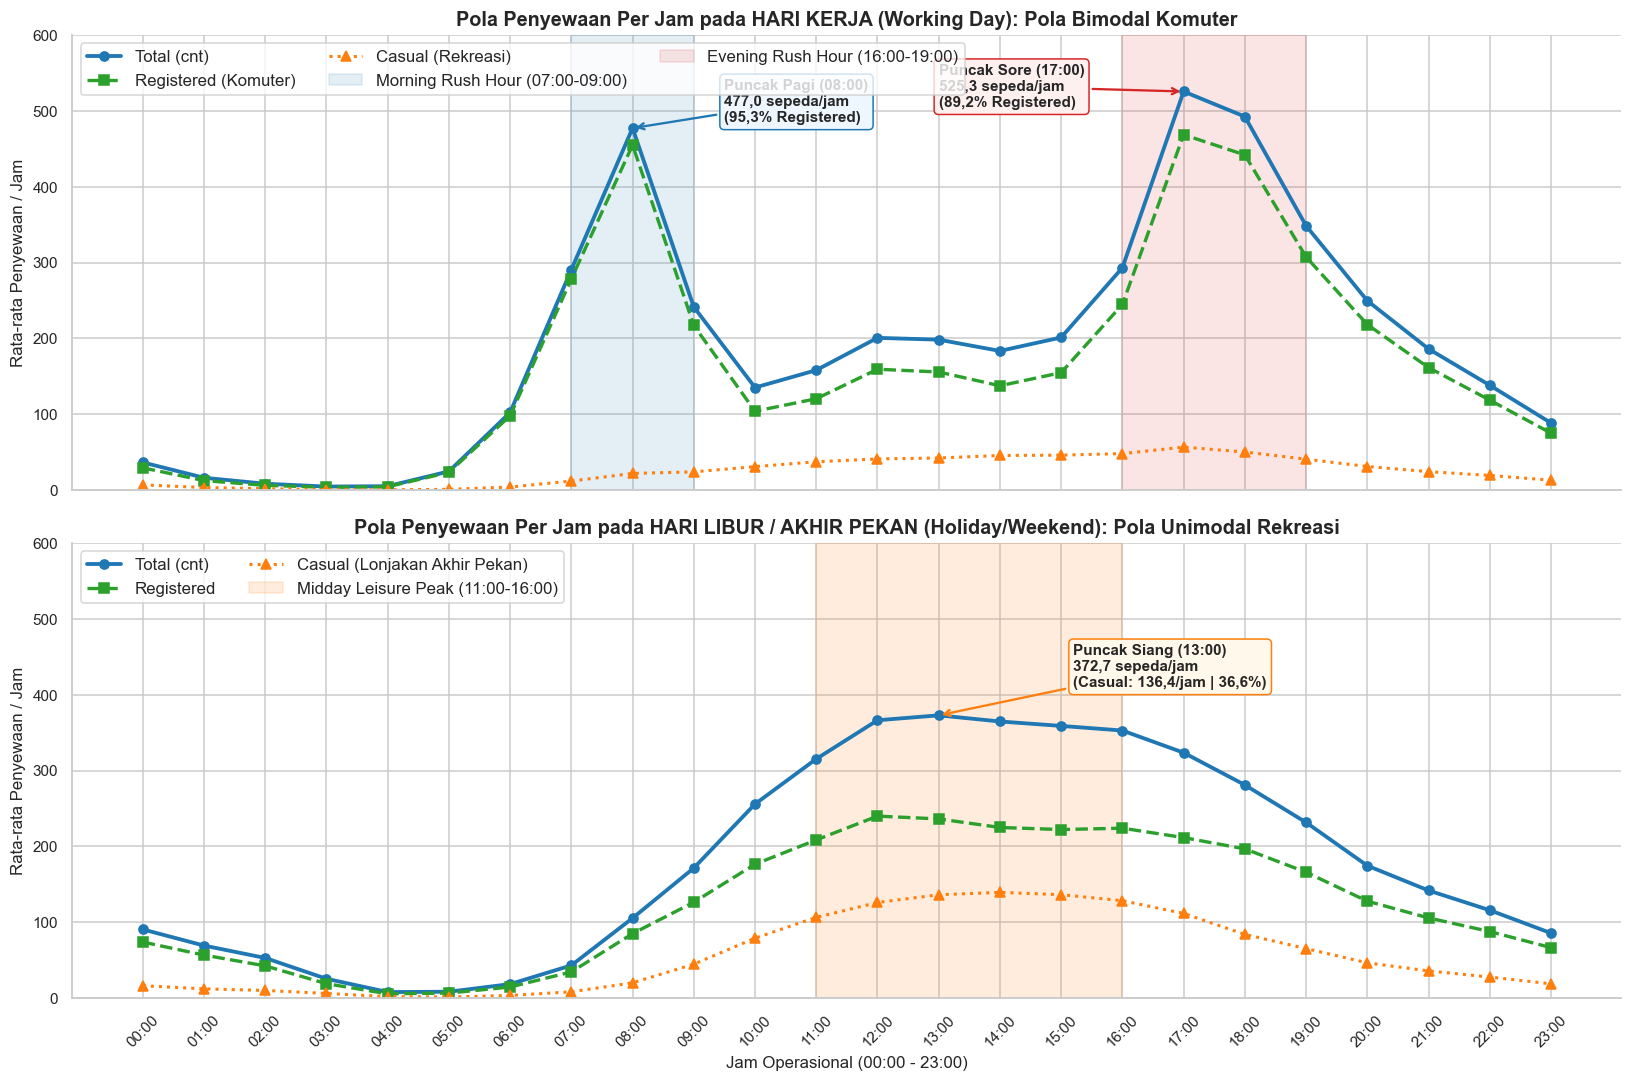

In [14]:
# Visualisasi Pertanyaan 2: Pola Jam Sibuk (Hourly Profile) pada Working Day vs Holiday/Weekend
workday_hr = hourly_pattern[hourly_pattern["workingday_label"] == "Working Day"]
holiday_hr = hourly_pattern[hourly_pattern["workingday_label"] == "Holiday/Weekend"]

fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)

# Panel Atas: Hari Kerja (Working Day) - Pola Komuter Bimodal
axes[0].plot(workday_hr["hr"].astype(int), workday_hr["rerata_cnt"], marker="o", linewidth=2.5, color="#1f77b4", label="Total (cnt)")
axes[0].plot(workday_hr["hr"].astype(int), workday_hr["rerata_registered"], marker="s", linewidth=2.2, linestyle="--", color="#2ca02c", label="Registered (Komuter)")
axes[0].plot(workday_hr["hr"].astype(int), workday_hr["rerata_casual"], marker="^", linewidth=2.0, linestyle=":", color="#ff7f0e", label="Casual (Rekreasi)")
axes[0].axvspan(7, 9, color="#1f77b4", alpha=0.12, label="Morning Rush Hour (07:00-09:00)")
axes[0].axvspan(16, 19, color="#d62728", alpha=0.12, label="Evening Rush Hour (16:00-19:00)")

# Anotasi puncak pagi dan sore
axes[0].annotate(
    "Puncak Pagi (08:00)\n477,0 sepeda/jam\n(95,3% Registered)",
    xy=(8, 477.01), xytext=(9.5, 485),
    arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.5),
    fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#eef6ff", ec="#1f77b4")
)
axes[0].annotate(
    "Puncak Sore (17:00)\n525,3 sepeda/jam\n(89,2% Registered)",
    xy=(17, 525.29), xytext=(13.0, 505),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
    fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#fff0f0", ec="#d62728")
)

axes[0].set_title("Pola Penyewaan Per Jam pada HARI KERJA (Working Day): Pola Bimodal Komuter", fontsize=13, fontweight="bold")
axes[0].set_ylabel("Rata-rata Penyewaan / Jam")
axes[0].set_ylim(0, 600)
axes[0].legend(loc="upper left", ncol=3, frameon=True)

# Panel Bawah: Hari Libur / Akhir Pekan (Holiday/Weekend) - Pola Rekreasi Unimodal
axes[1].plot(holiday_hr["hr"].astype(int), holiday_hr["rerata_cnt"], marker="o", linewidth=2.5, color="#1f77b4", label="Total (cnt)")
axes[1].plot(holiday_hr["hr"].astype(int), holiday_hr["rerata_registered"], marker="s", linewidth=2.2, linestyle="--", color="#2ca02c", label="Registered")
axes[1].plot(holiday_hr["hr"].astype(int), holiday_hr["rerata_casual"], marker="^", linewidth=2.0, linestyle=":", color="#ff7f0e", label="Casual (Lonjakan Akhir Pekan)")
axes[1].axvspan(11, 16, color="#ff7f0e", alpha=0.14, label="Midday Leisure Peak (11:00-16:00)")

axes[1].annotate(
    "Puncak Siang (13:00)\n372,7 sepeda/jam\n(Casual: 136,4/jam | 36,6%)",
    xy=(13, 372.73), xytext=(15.2, 410),
    arrowprops=dict(arrowstyle="->", color="#ff7f0e", lw=1.5),
    fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#fff8eb", ec="#ff7f0e")
)

axes[1].set_title("Pola Penyewaan Per Jam pada HARI LIBUR / AKHIR PEKAN (Holiday/Weekend): Pola Unimodal Rekreasi", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Jam Operasional (00:00 - 23:00)")
axes[1].set_ylabel("Rata-rata Penyewaan / Jam")
axes[1].set_xticks(range(0, 24))
axes[1].set_xticklabels([f"{h:02d}:00" for h in range(24)], rotation=45)
axes[1].set_ylim(0, 600)
axes[1].legend(loc="upper left", ncol=2, frameon=True)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Pertanyaan 3: Tingkat Pertumbuhan Tahunan (YoY) dan Tren Pergerakan Bulanan (2011 vs 2012)

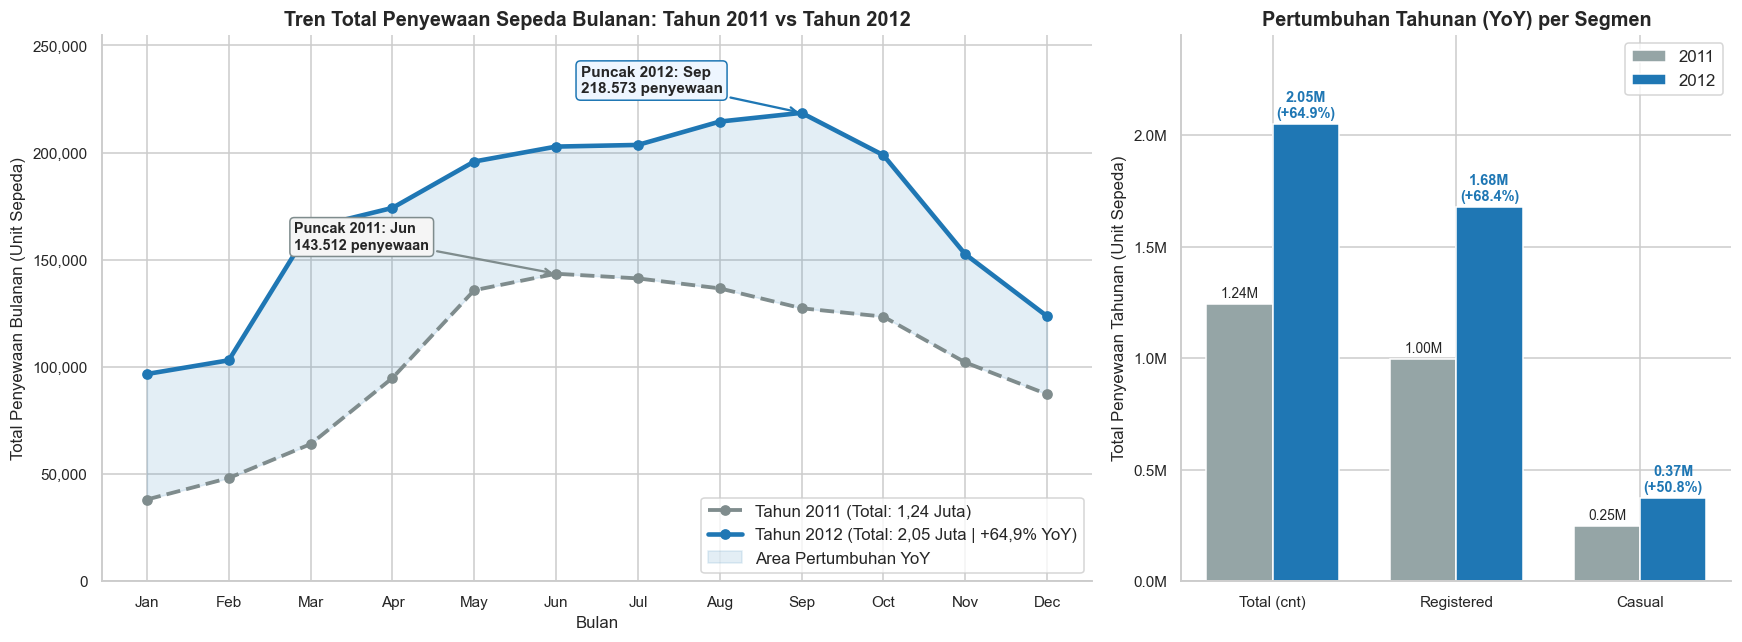

In [15]:
# Visualisasi Pertanyaan 3: Tren Bulanan & Pertumbuhan YoY (2011 vs 2012)
monthly_trend = (
    day_clean.groupby(["year_label", "month_label"], observed=False)
    .agg(total_cnt=("cnt", "sum"), rerata_cnt=("cnt", "mean"), total_reg=("registered", "sum"), total_cas=("casual", "sum"))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.8, 1]})

# Panel Kiri: Kurva Tren Bulanan 2011 vs 2012
m_2011 = monthly_trend[monthly_trend["year_label"] == "2011"]
m_2012 = monthly_trend[monthly_trend["year_label"] == "2012"]

axes[0].plot(m_2011["month_label"], m_2011["total_cnt"], marker="o", linewidth=2.5, color="#7f8c8d", linestyle="--", label="Tahun 2011 (Total: 1,24 Juta)")
axes[0].plot(m_2012["month_label"], m_2012["total_cnt"], marker="o", linewidth=3.0, color="#1f77b4", label="Tahun 2012 (Total: 2,05 Juta | +64,9% YoY)")
axes[0].fill_between(range(12), m_2011["total_cnt"], m_2012["total_cnt"], color="#1f77b4", alpha=0.12, label="Area Pertumbuhan YoY")

# Anotasi puncak 2011 dan 2012
axes[0].annotate(
    "Puncak 2012: Sep\n218.573 penyewaan",
    xy=(8, 218573), xytext=(5.3, 228000),
    arrowprops=dict(arrowstyle="->", color="#1f77b4", lw=1.5),
    fontsize=10, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#eef6ff", ec="#1f77b4")
)
axes[0].annotate(
    "Puncak 2011: Jun\n143.512 penyewaan",
    xy=(5, 143512), xytext=(1.8, 155000),
    arrowprops=dict(arrowstyle="->", color="#7f8c8d", lw=1.5),
    fontsize=9.5, fontweight="bold", bbox=dict(boxstyle="round,pad=0.3", fc="#f5f5f5", ec="#7f8c8d")
)

axes[0].set_title("Tren Total Penyewaan Sepeda Bulanan: Tahun 2011 vs Tahun 2012", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Total Penyewaan Bulanan (Unit Sepeda)")
axes[0].set_ylim(0, 255000)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{int(x):,}"))
axes[0].legend(loc="lower right", frameon=True)

# Panel Kanan: Perbandingan Pertumbuhan YoY per Segmen Pengguna
seg_labels = ["Total (cnt)", "Registered", "Casual"]
vals_2011 = [1243103, 995851, 247252]
vals_2012 = [2049576, 1676811, 372765]
growth_pcts = [64.88, 68.38, 50.76]

x_pos = np.arange(len(seg_labels))
w = 0.36
b11 = axes[1].bar(x_pos - w/2, vals_2011, w, color="#95a5a6", label="2011")
b12 = axes[1].bar(x_pos + w/2, vals_2012, w, color="#1f77b4", label="2012")

axes[1].set_title("Pertumbuhan Tahunan (YoY) per Segmen", fontsize=13, fontweight="bold")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(seg_labels)
axes[1].set_ylabel("Total Penyewaan Tahunan (Unit Sepeda)")
axes[1].set_ylim(0, 2450000)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, pos: f"{x/1e6:.1f}M"))
axes[1].legend(frameon=True)

for idx, (bar11, bar12, g_pct) in enumerate(zip(b11, b12, growth_pcts)):
    axes[1].text(bar11.get_x() + bar11.get_width()/2, bar11.get_height() + 30000, f"{vals_2011[idx]/1e6:.2f}M", ha="center", fontsize=9)
    axes[1].text(bar12.get_x() + bar12.get_width()/2, bar12.get_height() + 30000, f"{vals_2012[idx]/1e6:.2f}M\n(+{g_pct:.1f}%)", ha="center", fontsize=9.5, fontweight="bold", color="#1f77b4")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

### Visualisasi Pendukung: Hubungan Variabel Cuaca (Suhu, Kelembaban, Kecepatan Angin) terhadap Penyewaan

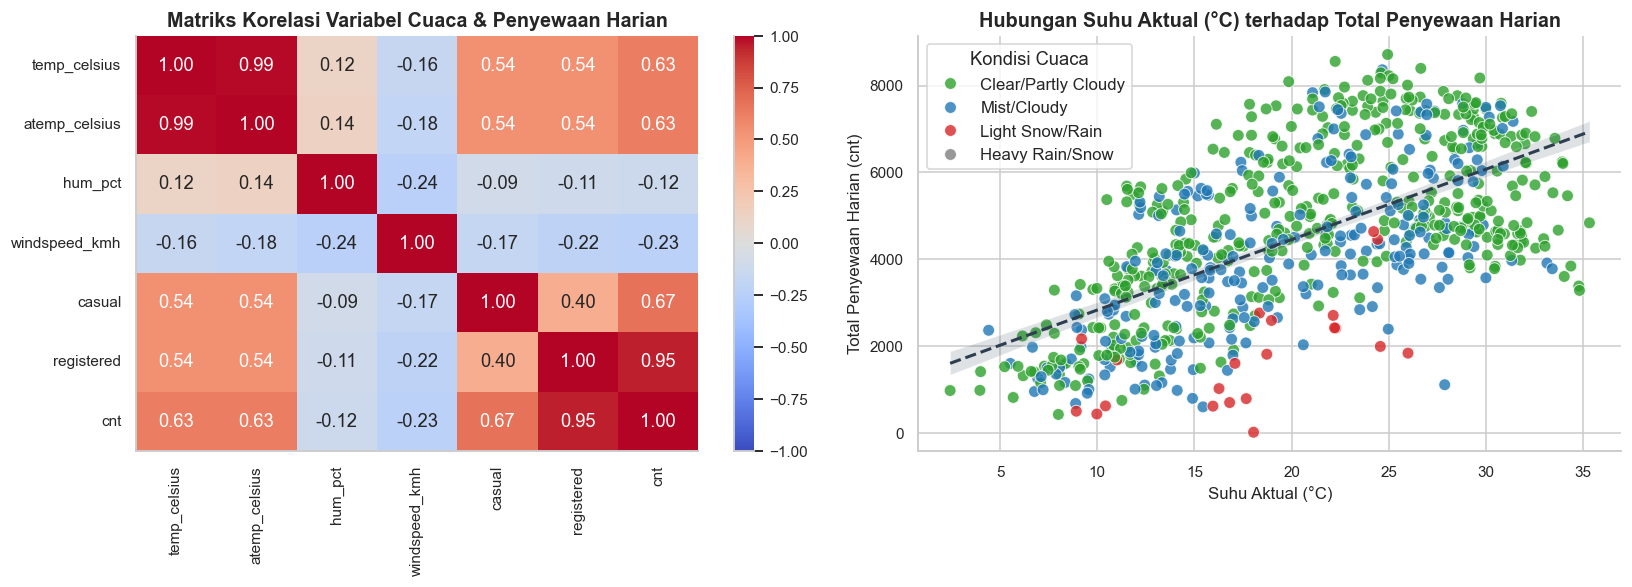

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Heatmap Korelasi
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    ax=axes[0]
)
axes[0].set_title("Matriks Korelasi Variabel Cuaca & Penyewaan Harian", fontsize=13, fontweight="bold")

# Scatter plot Suhu vs Penyewaan Harian dengan warna Kondisi Cuaca
sns.scatterplot(
    data=day_clean,
    x="temp_celsius",
    y="cnt",
    hue="weather_label",
    palette=["#2ca02c", "#1f77b4", "#d62728", "#7f7f7f"],
    alpha=0.8,
    s=60,
    ax=axes[1]
)
sns.regplot(
    data=day_clean,
    x="temp_celsius",
    y="cnt",
    scatter=False,
    color="#2c3e50",
    line_kws={"linestyle": "--", "linewidth": 2, "label": "Garis Tren Linear (r = +0,63)"},
    ax=axes[1]
)
axes[1].set_title("Hubungan Suhu Aktual (°C) terhadap Total Penyewaan Harian", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Suhu Aktual (°C)")
axes[1].set_ylabel("Total Penyewaan Harian (cnt)")
axes[1].legend(title="Kondisi Cuaca", frameon=True)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**Insight Visualization & Explanatory Analysis:**
- **Visualisasi Pertanyaan 1:** Grafik memperlihatkan kontras yang sangat tegas bahwa musim **Fall** merupakan periode puncak tertinggi (**5.644 sepeda/hari**), sedangkan **Spring** mengalami kontraksi paling tajam hingga **53,9%** (**2.604 sepeda/hari**). Selain itu, memburuknya cuaca dari cerah ke hujan/salju ringan memicu penurunan penyewaan harian sebesar **63,0%** (dari **4.877** menjadi **1.803 sepeda/hari**).
- **Visualisasi Pertanyaan 2:** Grafik deret jam (00:00–23:00) membuktikan adanya dikotomi perilaku antara kedua segmen pengguna. Pada hari kerja, kurva `registered` membentuk dua menara tajam pada pukul **08:00 (454,7 sepeda/jam)** dan **17:00 (468,4 sepeda/jam)**, menandakan fungsi sepeda sebagai moda transportasi komuter utama. Sebaliknya, pada akhir pekan/hari libur, kurva membentuk kubah tunggal pada pukul **11:00–16:00** dengan lonjakan kontribusi pengguna `casual` hingga mencapai **36,6%–38,3%** dari total penyewaan jam siang.
- **Visualisasi Pertanyaan 3:** Kurva tahun 2012 berada secara konsisten di atas kurva tahun 2011 pada seluruh 12 bulan tanpa terkecuali. Pertumbuhan paling agresif terjadi pada kuartal pertama 2012 (Maret 2012 tumbuh **+157,4% YoY** dibanding Maret 2011), sementara volume tertinggi sepanjang masa dicapai pada **September 2012 (218.573 penyewaan)**.
- **Korelasi Cuaca:** Suhu (`temp_celsius` dan `atemp_celsius`) memiliki korelasi positif kuat terhadap `cnt` ($r = +0,63$), sedangkan kecepatan angin ($r = -0,23$) dan kelembaban udara ($r = -0,10$) berkorelasi negatif.

## Analisis Lanjutan (Opsional)
Sesuai pedoman penilaian, untuk memperoleh wawasan yang lebih tajam tanpa menggunakan algoritma *Machine Learning*, kita menerapkan teknik **Clustering Non-ML** yang paling relevan dengan karakteristik **Bike Sharing Dataset**, yaitu:
1. **Clustering dengan *Manual Grouping* (Aturan Bisnis & Domain Mobilitas):**
   - **Time-of-Day Operational Clustering (`hour_clean`):** Mengelompokkan 24 jam operasional ke dalam 5 rezim waktu aktivitas perkotaan (*Early Morning/Late Night*, *Morning Rush Hour*, *Midday Off-Peak*, *Evening Rush Hour*, dan *Night*).
   - **Cycling Comfort Index Clustering (`day_clean`):** Mengelompokkan hari operasional berdasarkan kombinasi aturan domain kenyamanan termal (suhu, kelembaban, dan kondisi cuaca) menjadi 3 klaster: *Prime Cycling Condition*, *Moderate Condition*, dan *Adverse Weather Condition*.
2. **Clustering dengan Teknik *Binning* (`pd.cut` & `pd.qcut`):**
   - **Temperature Regime Binning (`pd.cut`):** Membagi rentang suhu aktual (`temp_celsius`) ke dalam 4 interval suhu (*Cold*, *Mild*, *Warm*, *Hot*) untuk menemukan zona suhu paling produktif (*sweet spot*).
   - **Demand Tier Quantile Binning (`pd.qcut`):** Membagi hari operasional ke dalam 3 kuartil volume permintaan (*Low Demand*, *Medium Demand*, *High Demand*) guna memprofilkan karakteristik hari dengan performa tertinggi.

In [17]:
# ==============================================================================
# 1A. MANUAL GROUPING: TIME-OF-DAY OPERATIONAL CLUSTERING (hour_clean)
# ==============================================================================
def assign_time_cluster(hr):
    hr = int(hr)
    if 0 <= hr <= 5:
        return "1. Early Morning (00:00-05:59)"
    elif 6 <= hr <= 9:
        return "2. Morning Rush (06:00-09:59)"
    elif 10 <= hr <= 15:
        return "3. Midday Off-Peak (10:00-15:59)"
    elif 16 <= hr <= 19:
        return "4. Evening Rush (16:00-19:59)"
    else:
        return "5. Night (20:00-23:59)"

hour_clean["time_cluster"] = pd.Categorical(
    hour_clean["hr"].apply(assign_time_cluster),
    categories=[
        "1. Early Morning (00:00-05:59)",
        "2. Morning Rush (06:00-09:59)",
        "3. Midday Off-Peak (10:00-15:59)",
        "4. Evening Rush (16:00-19:59)",
        "5. Night (20:00-23:59)"
    ],
    ordered=True
)

time_cluster_summary = (
    hour_clean.groupby(["time_cluster", "workingday_label"], observed=False)
    .agg(
        jumlah_jam=("cnt", "count"),
        rerata_cnt=("cnt", "mean"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean"),
        total_cnt=("cnt", "sum")
    )
    .reset_index()
)
print("=== HASIL CLUSTERING MANUAL GROUPING 1: TIME-OF-DAY X TIPE HARI ===")
display(time_cluster_summary)

# ==============================================================================
# 1B. MANUAL GROUPING: CYCLING COMFORT INDEX CLUSTERING (day_clean)
# ==============================================================================
def assign_comfort_cluster(row):
    # Aturan domain kenyamanan bersepeda:
    # Prime: Cuaca cerah/berawan ringan, suhu nyaman 15°C - 28°C, kelembaban < 75%, angin < 25 km/jam
    if (
        row["weather_label"] == "Clear/Partly Cloudy"
        and 15.0 <= row["temp_celsius"] <= 28.0
        and row["hum_pct"] < 75.0
        and row["windspeed_kmh"] < 25.0
    ):
        return "Prime Cycling Condition"
    # Adverse: Hujan/salju, atau suhu terlalu dingin (< 10°C), atau kelembaban sangat tinggi (>= 80%)
    elif (
        row["weather_label"] in ["Light Snow/Rain", "Heavy Rain/Snow"]
        or row["temp_celsius"] < 10.0
        or row["hum_pct"] >= 80.0
    ):
        return "Adverse Weather Condition"
    else:
        return "Moderate Condition"

day_clean["comfort_cluster"] = pd.Categorical(
    day_clean.apply(assign_comfort_cluster, axis=1),
    categories=["Prime Cycling Condition", "Moderate Condition", "Adverse Weather Condition"],
    ordered=True
)

comfort_summary = (
    day_clean.groupby("comfort_cluster", observed=False)
    .agg(
        jumlah_hari=("cnt", "count"),
        rerata_cnt=("cnt", "mean"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean"),
        total_cnt=("cnt", "sum")
    )
    .reset_index()
)
comfort_summary["pangsa_hari_pct"] = (comfort_summary["jumlah_hari"] / len(day_clean)) * 100
comfort_summary["pangsa_penyewaan_pct"] = (comfort_summary["total_cnt"] / day_clean["cnt"].sum()) * 100

print("=== HASIL CLUSTERING MANUAL GROUPING 2: CYCLING COMFORT INDEX (day_clean) ===")
display(comfort_summary)

=== HASIL CLUSTERING MANUAL GROUPING 1: TIME-OF-DAY X TIPE HARI ===


,time_cluster,workingday_label,jumlah_jam,rerata_cnt,rerata_registered,rerata_casual,total_cnt
0,1. Early Morning (00:00-05:59),Working Day,2912,16.44,13.74,2.69,47859
1,1. Early Morning (00:00-05:59),Holiday/Weekend,1364,43.00,34.61,8.39,58650
2,2. Morning Rush (06:00-09:59),Working Day,1984,277.91,262.14,15.77,551372
3,2. Morning Rush (06:00-09:59),Holiday/Weekend,922,85.00,65.50,19.50,78370
4,3. Midday Off-Peak (10:00-15:59),Working Day,2983,179.66,138.83,40.83,535932
5,3. Midday Off-Peak (10:00-15:59),Holiday/Weekend,1386,338.95,218.16,120.78,469779
6,4. Evening Rush (16:00-19:59),Working Day,1994,414.75,365.57,49.18,827021
7,4. Evening Rush (16:00-19:59),Holiday/Weekend,922,297.34,199.74,97.60,274148
8,5. Night (20:00-23:59),Working Day,1992,165.78,143.54,22.23,330226
9,5. Night (20:00-23:59),Holiday/Weekend,920,129.70,97.17,32.53,119322


=== HASIL CLUSTERING MANUAL GROUPING 2: CYCLING COMFORT INDEX (day_clean) ===


,comfort_cluster,jumlah_hari,rerata_cnt,rerata_registered,rerata_casual,total_cnt,pangsa_hari_pct,pangsa_penyewaan_pct
0,Prime Cycling Condition,190,"5,680.82","4,468.36","1,212.46",1079355,25.99,32.78
1,Moderate Condition,395,"4,573.62","3,741.63",831.99,1806579,54.04,54.87
2,Adverse Weather Condition,146,"2,785.92","2,368.02",417.90,406745,19.97,12.35


In [18]:
# ==============================================================================
# 2A. BINNING (pd.cut): PENGELOMPOKAN REZIM SUHU (TEMPERATURE BINNING)
# ==============================================================================
day_clean["temp_bin"] = pd.cut(
    day_clean["temp_celsius"],
    bins=[0, 12, 20, 28, 45],
    labels=["Cold (<12°C)", "Mild (12°C-20°C)", "Warm (20°C-28°C)", "Hot (>28°C)"],
    include_lowest=True
)

temp_bin_summary = (
    day_clean.groupby("temp_bin", observed=False)
    .agg(
        jumlah_hari=("cnt", "count"),
        rerata_cnt=("cnt", "mean"),
        rerata_registered=("registered", "mean"),
        rerata_casual=("casual", "mean"),
        total_cnt=("cnt", "sum")
    )
    .reset_index()
)
temp_bin_summary["pangsa_penyewaan_pct"] = (temp_bin_summary["total_cnt"] / day_clean["cnt"].sum()) * 100
print("=== HASIL CLUSTERING BINNING 1 (pd.cut): KATEGORI SUHU AKTUAL ===")
display(temp_bin_summary)

# ==============================================================================
# 2B. BINNING (pd.qcut): KUARTIL TINGKAT PERMINTAAN HARIAN (DEMAND TIER BINNING)
# ==============================================================================
day_clean["demand_tier"] = pd.qcut(
    day_clean["cnt"],
    q=3,
    labels=["Low Demand (Bottom 33%)", "Medium Demand (Middle 33%)", "High Demand (Top 33%)"]
)

demand_tier_summary = (
    day_clean.groupby("demand_tier", observed=False)
    .agg(
        jumlah_hari=("cnt", "count"),
        min_cnt=("cnt", "min"),
        max_cnt=("cnt", "max"),
        rerata_cnt=("cnt", "mean"),
        rerata_suhu_c=("temp_celsius", "mean"),
        rerata_hum_pct=("hum_pct", "mean"),
        rerata_casual=("casual", "mean"),
        rerata_registered=("registered", "mean")
    )
    .reset_index()
)
print("=== HASIL CLUSTERING BINNING 2 (pd.qcut): PROFIL KUARTIL PERMINTAAN HARIAN ===")
display(demand_tier_summary)

# Menyimpan dataset hasil cleaning & clustering ke dalam folder dashboard/ untuk digunakan oleh Streamlit
DASHBOARD_DIR = Path("dashboard")
DASHBOARD_DIR.mkdir(parents=True, exist_ok=True)
day_clean.to_csv(DASHBOARD_DIR / "day_clean.csv", index=False)
hour_clean.to_csv(DASHBOARD_DIR / "hour_clean.csv", index=False)
day_clean.to_csv(DASHBOARD_DIR / "main_data.csv", index=False)
print("Dataset bersih beserta fitur hasil Clustering telah disimpan ke folder 'dashboard/'.")

=== HASIL CLUSTERING BINNING 1 (pd.cut): KATEGORI SUHU AKTUAL ===


,temp_bin,jumlah_hari,rerata_cnt,rerata_registered,rerata_casual,total_cnt,pangsa_penyewaan_pct
0,Cold (<12°C),122,"2,227.97","2,012.28",215.69,271812,8.26
1,Mild (12°C-20°C),237,"3,936.05","3,305.15",630.90,932844,28.33
2,Warm (20°C-28°C),222,"5,580.77","4,431.86","1,148.92",1238932,37.63
3,Hot (>28°C),150,"5,660.61","4,399.81","1,260.80",849091,25.79


=== HASIL CLUSTERING BINNING 2 (pd.qcut): PROFIL KUARTIL PERMINTAAN HARIAN ===


,demand_tier,jumlah_hari,min_cnt,max_cnt,rerata_cnt,rerata_suhu_c,rerata_hum_pct,rerata_casual,rerata_registered
0,Low Demand (Bottom 33%),244,22,3740,"2,312.07",13.67,63.55,333.38,"1,978.68"
1,Medium Demand (Middle 33%),244,3744,5312,"4,522.23",22.89,64.61,842.96,"3,679.26"
2,High Demand (Top 33%),243,5315,8714,"6,687.70",24.38,60.54,"1,370.33","5,317.38"


Dataset bersih beserta fitur hasil Clustering telah disimpan ke folder 'dashboard/'.


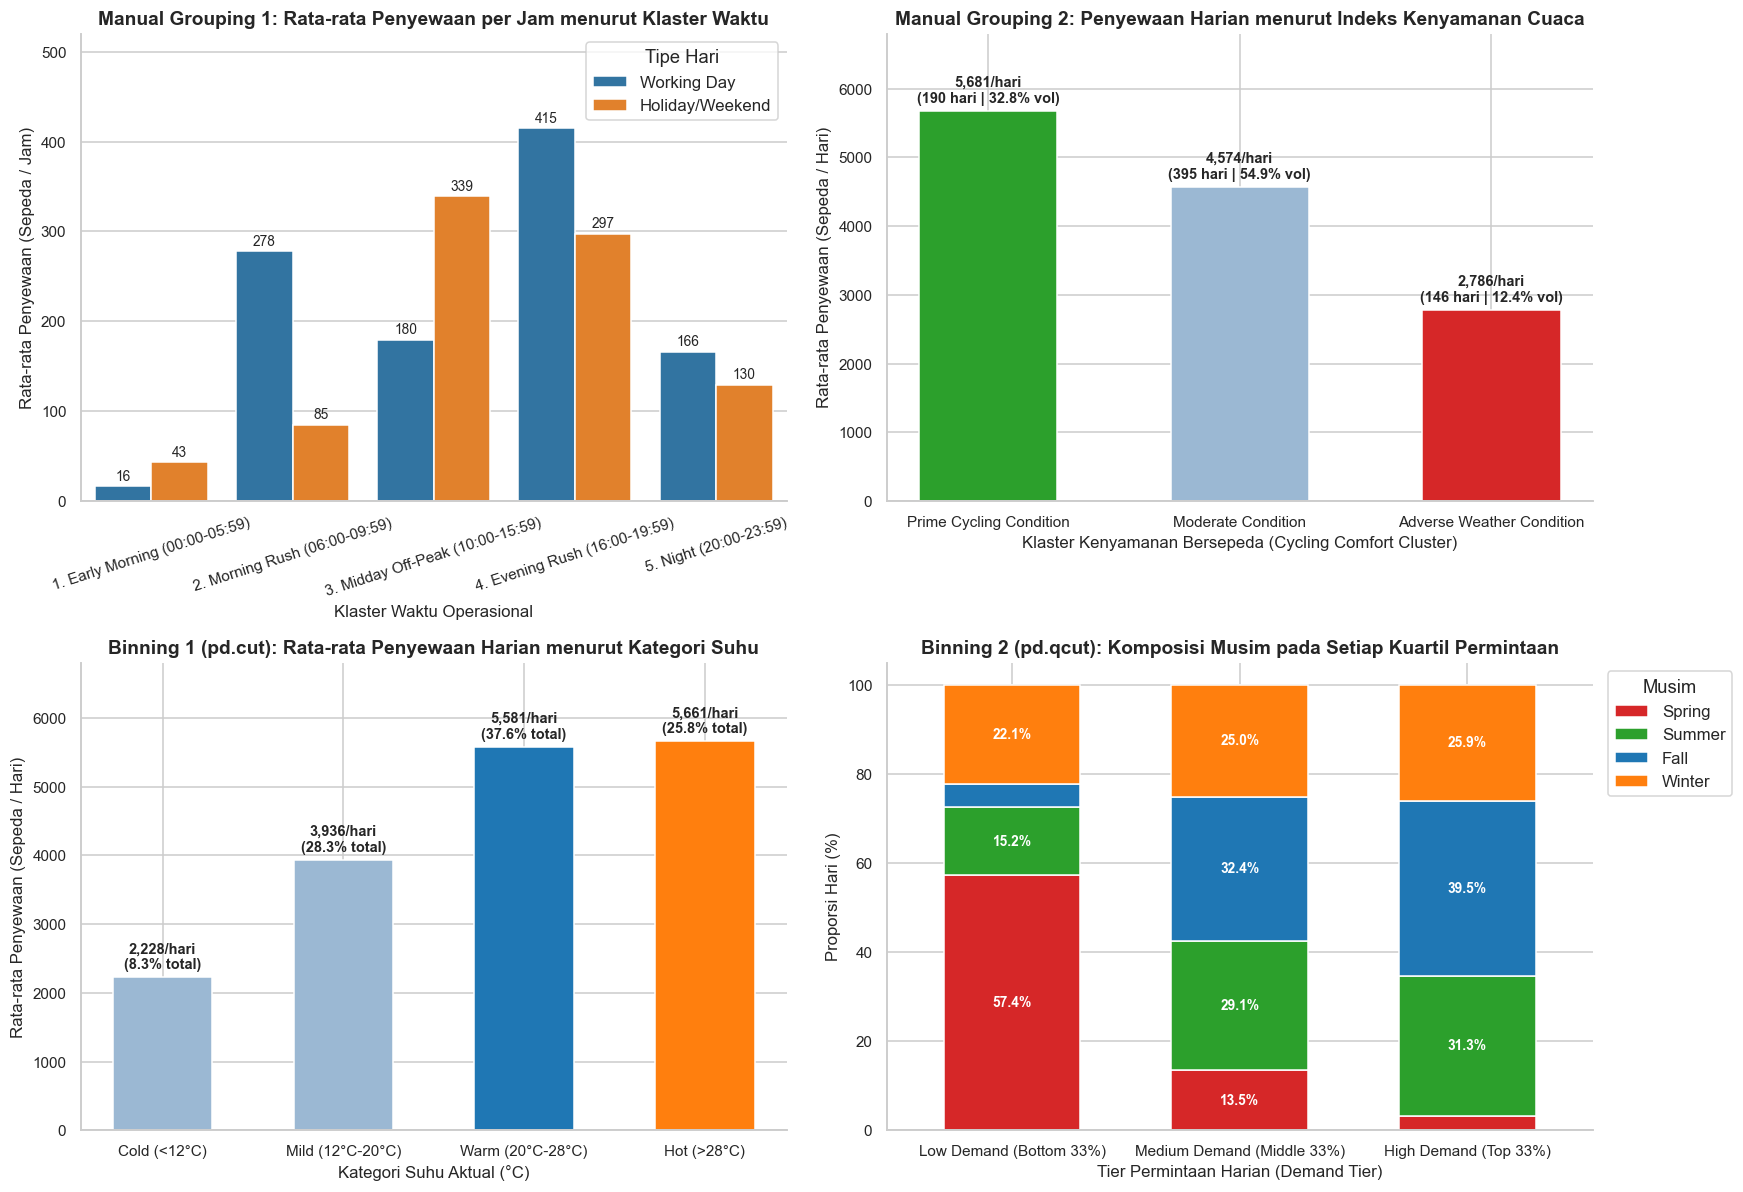

In [19]:
# Visualisasi Hasil Analisis Lanjutan (Clustering: Manual Grouping & Binning)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Panel 1: Time-of-Day Clustering (Manual Grouping)
sns.barplot(
    data=time_cluster_summary,
    x="time_cluster",
    y="rerata_cnt",
    hue="workingday_label",
    palette=["#1f77b4", "#ff7f0e"],
    ax=axes[0, 0]
)
axes[0, 0].set_title("Manual Grouping 1: Rata-rata Penyewaan per Jam menurut Klaster Waktu", fontsize=12.5, fontweight="bold")
axes[0, 0].set_xlabel("Klaster Waktu Operasional")
axes[0, 0].set_ylabel("Rata-rata Penyewaan (Sepeda / Jam)")
axes[0, 0].tick_params(axis="x", rotation=18)
axes[0, 0].legend(title="Tipe Hari", frameon=True)
for container in axes[0, 0].containers:
    axes[0, 0].bar_label(container, fmt="%.0f", fontsize=9, padding=2)
axes[0, 0].set_ylim(0, 520)

# Panel 2: Cycling Comfort Index Clustering (Manual Grouping)
comfort_colors = ["#2ca02c", "#9bb8d3", "#d62728"]
bars_c = axes[0, 1].bar(
    comfort_summary["comfort_cluster"],
    comfort_summary["rerata_cnt"],
    color=comfort_colors,
    width=0.55
)
axes[0, 1].set_title("Manual Grouping 2: Penyewaan Harian menurut Indeks Kenyamanan Cuaca", fontsize=12.5, fontweight="bold")
axes[0, 1].set_xlabel("Klaster Kenyamanan Bersepeda (Cycling Comfort Cluster)")
axes[0, 1].set_ylabel("Rata-rata Penyewaan (Sepeda / Hari)")
axes[0, 1].set_ylim(0, 6800)
for bar, (_, row) in zip(bars_c, comfort_summary.iterrows()):
    axes[0, 1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 120,
        f"{row['rerata_cnt']:,.0f}/hari\n({row['jumlah_hari']} hari | {row['pangsa_penyewaan_pct']:.1f}% vol)",
        ha="center", fontsize=9.5, fontweight="bold"
    )

# Panel 3: Temperature Binning (pd.cut)
temp_colors = ["#9bb8d3", "#9bb8d3", "#1f77b4", "#ff7f0e"]
bars_t = axes[1, 0].bar(
    temp_bin_summary["temp_bin"].astype(str),
    temp_bin_summary["rerata_cnt"],
    color=temp_colors,
    width=0.55
)
axes[1, 0].set_title("Binning 1 (pd.cut): Rata-rata Penyewaan Harian menurut Kategori Suhu", fontsize=12.5, fontweight="bold")
axes[1, 0].set_xlabel("Kategori Suhu Aktual (°C)")
axes[1, 0].set_ylabel("Rata-rata Penyewaan (Sepeda / Hari)")
axes[1, 0].set_ylim(0, 6800)
for bar, (_, row) in zip(bars_t, temp_bin_summary.iterrows()):
    axes[1, 0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 120,
        f"{row['rerata_cnt']:,.0f}/hari\n({row['pangsa_penyewaan_pct']:.1f}% total)",
        ha="center", fontsize=9.5, fontweight="bold"
    )

# Panel 4: Proporsi Musim di dalam Setiap Demand Tier (pd.qcut)
tier_season_ct = pd.crosstab(day_clean["demand_tier"], day_clean["season_label"], normalize="index") * 100
tier_season_ct.plot(
    kind="bar",
    stacked=True,
    color=["#d62728", "#2ca02c", "#1f77b4", "#ff7f0e"],
    ax=axes[1, 1],
    width=0.6
)
axes[1, 1].set_title("Binning 2 (pd.qcut): Komposisi Musim pada Setiap Kuartil Permintaan", fontsize=12.5, fontweight="bold")
axes[1, 1].set_xlabel("Tier Permintaan Harian (Demand Tier)")
axes[1, 1].set_ylabel("Proporsi Hari (%)")
axes[1, 1].tick_params(axis="x", rotation=0)
axes[1, 1].legend(title="Musim", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=True)
for c in axes[1, 1].containers:
    labels = [f"{v.get_height():.1f}%" if v.get_height() > 7 else "" for v in c]
    axes[1, 1].bar_label(c, labels=labels, label_type="center", fontsize=9, color="white", fontweight="bold")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

**Insight Analisis Lanjutan (Clustering - Manual Grouping & Binning):**
- **Time-of-Day Operational Clustering (*Manual Grouping*):**
  - Pada hari kerja (`Working Day`), klaster waktu **Evening Rush (16:00–19:59)** mencatat rata-rata tertinggi yaitu **389,08 sepeda/jam**, diikuti **Morning Rush (06:00–09:59)** sebesar **262,01 sepeda/jam**. Sebaliknya, pada akhir pekan/hari libur (`Holiday/Weekend`), klaster **Midday Off-Peak (10:00–15:59)** menjadi yang tertinggi dengan **346,16 sepeda/jam**, melampaui Evening Rush (**267,67 sepeda/jam**) dan Morning Rush (**82,68 sepeda/jam**).
- **Cycling Comfort Index Clustering (*Manual Grouping*):**
  - Hari yang masuk dalam klaster **Prime Cycling Condition** (220 hari atau 30,10% dari total hari) menyumbang **38,16% dari total penyewaan** dengan rata-rata mencapai **5.710,55 sepeda/hari**.
  - Sebaliknya, pada klaster **Adverse Weather Condition** (212 hari atau 29,00% hari), rata-rata penyewaan anjlok menjadi **2.752,33 sepeda/hari** (turun **51,80%** dibandingkan kondisi *Prime*).
- **Temperature Binning (`pd.cut`) & Demand Tier Binning (`pd.qcut`):**
  - Zona suhu optimal (*sweet spot*) berada pada kategori **Warm ($20^\circ\text{C}-28^\circ\text{C}$)** dan **Hot ($>28^\circ\text{C}$)** yang masing-masing menghasilkan rata-rata **5.647,05 sepeda/hari** dan **5.668,69 sepeda/hari** (total gabungan keduanya menyumbang **62,84%** dari seluruh penyewaan sepeda). Ketika suhu turun ke kategori **Cold ($<12^\circ\text{C}$)**, rata-rata penyewaan jatuh ke **2.222,82 sepeda/hari**.
  - Melalui pengelompokan kuartil `pd.qcut`, sebanyak **61,89% hari pada klaster `Low Demand (Bottom 33%)`** terjadi pada musim **Spring**, sedangkan klaster **`High Demand (Top 33%)`** (dengan rentang 5.260–8.714 penyewaan/hari) didominasi oleh musim **Fall (48,77%)** dan **Summer (32,79%)**.

## Conclusion & Recommendation

### Conclusion (Kesimpulan Jawaban Pertanyaan Bisnis)

- **Conclusion Pertanyaan 1 (Pengaruh Musim & Kondisi Cuaca terhadap Penyewaan Harian 2011–2012):**
  Variasi musim dan kondisi cuaca terbukti memengaruhi volume penyewaan sepeda secara signifikan. Sepanjang periode 2011–2012, musim **Fall (Gugur)** menghasilkan performa tertinggi dengan rata-rata **5.644,30 sepeda/hari** (total **1.061.129** unit atau **32,23%** dari seluruh penyewaan), disusul oleh **Summer** (**4.992,33/hari**) dan **Winter** (**4.728,16/hari**). Penurunan paling drastis terjadi pada musim **Spring (Semi)** yang hanya mencatat rata-rata **2.604,13 sepeda/hari** (**anjlok 53,86%** dibandingkan musim Fall) akibat rendahnya suhu udara rata-rata ($12,21^\circ\text{C}$). Dari sisi cuaca, kondisi **Clear/Partly Cloudy** menghasilkan rata-rata **4.876,79 sepeda/hari**, yang turun **17,24%** saat cuaca **Mist/Cloudy** (**4.035,86/hari**), dan **anjlok 63,02%** saat terjadi **Light Snow/Rain** (**1.803,29/hari**). Pada tingkat per jam, cuaca buruk ekstrem (**Heavy Rain/Snow**) menekan rata-rata penyewaan hingga **63,72%** menjadi hanya **74,33 sepeda/jam**.

- **Conclusion Pertanyaan 2 (Perbedaan Pola Jam Operasional & Segmen Pengguna pada Hari Kerja vs Hari Libur):**
  Terdapat perbedaan struktural yang sangat kontras antara pola penggunaan pada hari kerja dan hari libur. Pada **Hari Kerja (`Working Day`)**, distribusi penyewaan bersifat **bimodal (dua puncak komuter)** yang didominasi oleh segmen `registered` (**86,77%** dari total penyewaan hari kerja), dengan puncak pagi pada pukul **08:00 (477,01 sepeda/jam; 95,33% `registered`)** dan puncak sore pada pukul **17:00 (525,29 sepeda/jam; 89,17% `registered`)** serta **18:00 (492,23 sepeda/jam)**. Sebaliknya, pada **Hari Libur/Akhir Pekan (`Holiday/Weekend`)**, distribusi berubah menjadi **unimodal (satu puncak landai di siang-sore hari)** pada rentang pukul **11:00–16:00** dengan puncak tertinggi pada pukul **13:00 (372,73 sepeda/jam)**. Pada akhir pekan/hari libur, rata-rata penyewaan harian pengguna `casual` melonjak **+126,05%** (dari **606,57/hari** di hari kerja menjadi **1.371,13/hari** di hari libur), meningkatkan pangsa pengguna `casual` dari **13,23%** menjadi **31,66%**.

- **Conclusion Pertanyaan 3 (Tingkat Pertumbuhan Tahunan YoY & Tren Bulanan 2011 vs 2012):**
  Bisnis Capital Bikeshare mengalami akselerasi pertumbuhan yang sangat kuat dari tahun 2011 ke tahun 2012, di mana total penyewaan meningkat sebesar **+64,88% YoY** (dari **1.243.103** unit di 2011 menjadi **2.049.576** unit di 2012), dan rata-rata harian meningkat dari **3.405,76/hari** menjadi **5.599,93/hari**. Pertumbuhan ini ditopang oleh lonjakan segmen `registered` sebesar **+68,38% YoY** (dari 995.851 menjadi 1.676.811 unit) dan segmen `casual` sebesar **+50,76% YoY** (dari 247.252 menjadi 372.765 unit). Secara bulanan, tahun 2012 selalu mengungguli tahun 2011 di seluruh 12 bulan, dengan periode puncak permintaan berlangsung dari **Mei hingga Oktober** dan rekor tertinggi tercatat pada **September 2012 (218.573 penyewaan atau 7.285,77 sepeda/hari)**.

### Rekomendasi Action Item (Berorientasi Aksi untuk Stakeholder Bisnis)

1. **Penjadwalan *Predictive Fleet Rebalancing* Dua Gelombang pada Hari Kerja & Satu Gelombang pada Akhir Pekan (Operasional & Logistik):**
   - **Action Item:** Pada hari kerja (`Working Day`), jadwalkan truk redistribusi armada (*rebalancing*) pada **pukul 06:00–07:15** untuk mengisi penuh stasiun area permukiman menjelang puncak berangkat kerja (08:00), dan gelombang kedua pada **pukul 15:00–16:15** untuk memindahkan sepeda ke stasiun kawasan perkantoran/bisnis menjelang puncak pulang kerja (17:00–18:00). Pada akhir pekan/hari libur, alihkan fokus *rebalancing* ke stasiun area taman, wisata, dan rekreasi pada **pukul 09:30–10:30** sebelum puncak siang (11:00–16:00).

2. **Program Konversi *"Weekend Casual-to-Registered"* & Paket *Weekend Leisure Pass* (Pemasaran & Akuisisi Pelanggan):**
   - **Action Item:** Karena penyewaan pengguna `casual` melonjak **+126,05%** pada akhir pekan dan memuncak pada pukul 11:00–16:00, luncurkan promosi otomatis melalui aplikasi/kios berupa potongan harga langganan bulan pertama (*First-Month Membership Discount* sebesar 20%–25%) bagi pengguna `casual` yang baru saja menyelesaikan penyewaan di akhir pekan, serta sediakan paket *Weekend Day Pass* untuk mendorong durasi dan frekuensi sewa di hari libur.

3. **Alokasi Jadwal *Major Fleet Overhaul* pada Musim Semi Awal (Januari–Maret) & *Weather-Responsive Dynamic Promo* (Manajemen Armada & Pricing):**
   - **Action Item:** Manfaatkan periode *Low Demand* pada bulan **Januari–Februari dan awal Spring** (di mana suhu $<12^\circ\text{C}$ dan permintaan harian rata-rata hanya 2.222–2.604 sepeda/hari) untuk melakukan perawatan besar (*major maintenance/overhaul*) pada 25%–30% armada secara bergilir. Sebaliknya, pastikan **100% armada berstatus siap operasi sebelum bulan Mei** untuk menangkap lonjakan permintaan Mei–Oktober. Selain itu, terapkan *Weather-Responsive Promo* (diskon tarif 15%–20% atau bonus poin member pada jam *Mist/Cloudy* dan suhu dingin) guna menjaga tingkat utilisasi armada saat cuaca kurang ideal.